# Laboratorio 3 — Clasificación

**Curso:** Aprendizaje de Máquina (ISIS2611) · **Integrantes:** Angel Felipe Restrepo Castillo — 201914073 · Laura Valentina Jimenez Tovar — 201924116

**Objetivo.** Construir y comparar modelos de clasificación (regresión logística, árbol de decisión y Random Forest) para anticipar si un conductor aceptará un cupón de **Cafetería** o de **Restaurante(<20)**, evaluar el efecto del desbalance de clases, identificar las variables más relevantes y discutir riesgos de sesgo al personalizar con datos demográficos.

## Configuración del entorno

Se cargan las librerías, se fija la semilla global (`SEED = 42`) para que los resultados sean reproducibles y se definen los colores usados en las gráficas.

In [1]:
import os, re, warnings
os.environ["PYTHONWARNINGS"] = "ignore"          # también silencia los procesos paralelos de GridSearchCV
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GroupKFold, GridSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay)

# imbalanced-learn (si no está instalado: %pip install imbalanced-learn)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

COLOR_SI, COLOR_NO = "#2a7fba", "#e8833a"      # colores consistentes: Sí acepta / No acepta
print("Librerías cargadas. Semilla global:", SEED)

Librerías cargadas. Semilla global: 42


# 1. Exploración de los datos

La exploración se organiza según las dimensiones de calidad de datos (**validez, consistencia, completitud, unicidad y valores atípicos**) y se complementa con el análisis de cada subconjunto (**Cafetería** y **Restaurante(<20)**) y de la distribución de la variable objetivo `acepta_cupon`.

## 1.1 Carga de datos y tipos de variables

In [2]:
def ruta_datos(nombre):
    """Busca el archivo en ./data, en la carpeta actual o en la carpeta de cargas del entorno."""
    for base in [Path("./data"), Path("."), Path("/mnt/user-data/uploads")]:
        if (base / nombre).exists():
            return base / nombre
    raise FileNotFoundError(f"No se encontró {nombre}. Colóquelo en ./data/")

df_raw        = pd.read_excel(ruta_datos("Lab3_Datos.xlsx"))
datos_prueba  = pd.read_excel(ruta_datos("Lab3_datos_Prueba.xlsx"))
diccionario   = pd.read_excel(ruta_datos("Lab3_diccionario_Datos.xlsx"))

print("Datos etiquetados :", df_raw.shape)
print("Datos de prueba   :", datos_prueba.shape, "(sin la columna acepta_cupon)")
print("Diccionario       :", diccionario.shape)

resumen_tipos = pd.DataFrame({
    "Tipo (diccionario)": diccionario.set_index("Variable")["Tipo"],
    "dtype en pandas": df_raw.dtypes.astype(str),
    "Valores distintos": df_raw.nunique(),
}).loc[df_raw.columns]
display(resumen_tipos)

Datos etiquetados : (12664, 26)
Datos de prueba   : (20, 25) (sin la columna acepta_cupon)
Diccionario       : (26, 3)


,Tipo (diccionario),dtype en pandas,Valores distintos
destino,Categórica nominal,str,3
acompanante,Categórica nominal,str,4
clima,Categórica nominal,str,3
temperatura,Numérica entero,int64,3
hora,Categórica ordinal,str,5
cupon,Categórica nominal,str,5
vigencia_cupon,Categórica nominal,str,2
genero,Categórica nominal,str,2
edad,Categórica ordinal,str,8
estado_civil,Categórica nominal,str,5


## 1.2 Validez: coherencia con el diccionario de datos

In [3]:
# --- VALIDEZ: ¿todos los valores observados están contemplados en el diccionario? ---
# (se compara ignorando espacios y mayúsculas, para detectar diferencias reales de contenido)
norm = lambda s: re.sub(r"\s+", "", str(s)).lower()
desc = diccionario.set_index("Variable")["Descripción"].to_dict()

filas = []
for col in df_raw.columns:
    if col in ("temperatura", "ocupacion", "acepta_cupon"):
        continue
    observados = df_raw[col].dropna().unique()
    fuera = [v for v in observados if norm(v) not in norm(desc[col])]
    if fuera:
        filas.append({"Variable": col, "Valores observados que no aparecen en el diccionario": fuera})
display(pd.DataFrame(filas) if filas else "Sin discrepancias")

# Diferencia de formato detectada: el diccionario escribe los rangos de ingreso sin espacios ("$12.500-$24.999")
print("Ejemplo en el diccionario:", re.findall(r"\$12\.500\s*-\s*\$24\.999", desc["ingreso"])[0])
print("Ejemplo en los datos     :", [v for v in df_raw["ingreso"].unique() if v.startswith("$12.500")][0])

,Variable,Valores observados que no aparecen en el diccionario
0,vehiculo,[Carro muy viejo para instalarle Onstar :D]


Ejemplo en el diccionario: $12.500-$24.999
Ejemplo en los datos     : $12.500 - $24.999


## 1.3 Consistencia: reglas lógicas entre variables

In [4]:
# --- CONSISTENCIA: reglas lógicas entre variables ---
d = df_raw
reglas = pd.DataFrame([
    ("temperatura ∈ {30, 55, 80} (rango del diccionario)",
     d["temperatura"].isin([30, 55, 80]).all(), "Sin problema"),
    ("misma_direccion y direccion_opuesta son complementarias (una es Sí cuando la otra es No)",
     ((d["misma_direccion"] == "Sí") != (d["direccion_opuesta"] == "Sí")).all(), "Redundancia total → se elimina una"),
    ("tiempo_cupon_mayor_25min = Sí ⇒ tiempo_cupon_mayor_15min = Sí",
     (~((d["tiempo_cupon_mayor_25min"] == "Sí") & (d["tiempo_cupon_mayor_15min"] == "No"))).all(), "Variables anidadas; se conservan ambas"),
    ("tiempo_cupon_mayor_5min es constante",
     d["tiempo_cupon_mayor_5min"].nunique() == 1, "Varianza cero → se elimina"),
    ("clima Nevado ⇒ 30 °F  y  Lluvioso ⇒ 55 °F",
     (d.loc[d.clima == "Nevado", "temperatura"].eq(30).all()) and (d.loc[d.clima == "Lluvioso", "temperatura"].eq(55).all()),
     "temperatura y clima están fuertemente ligadas (colinealidad parcial)"),
], columns=["Regla", "¿Se cumple?", "Implicación para el modelado"])
display(reglas)

print("\nTabulación clima × temperatura:")
display(pd.crosstab(d["clima"], d["temperatura"]))
print("Tabulación misma_direccion × direccion_opuesta:")
display(pd.crosstab(d["misma_direccion"], d["direccion_opuesta"]))

,Regla,¿Se cumple?,Implicación para el modelado
0,"temperatura ∈ {30, 55, 80} (rango del diccionario)",True,Sin problema
1,misma_direccion y direccion_opuesta son complementarias (una es Sí cuando la...,True,Redundancia total → se elimina una
2,tiempo_cupon_mayor_25min = Sí ⇒ tiempo_cupon_mayor_15min = Sí,True,Variables anidadas; se conservan ambas
3,tiempo_cupon_mayor_5min es constante,True,Varianza cero → se elimina
4,clima Nevado ⇒ 30 °F y Lluvioso ⇒ 55 °F,True,temperatura y clima están fuertemente ligadas (colinealidad parcial)



Tabulación clima × temperatura:


temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


Tabulación misma_direccion × direccion_opuesta:


direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


## 1.4 Completitud: valores faltantes

,Faltantes,% faltantes
vehiculo,12556,99.15
frecuencia_cafeteria,217,1.71
frecuencia_restaurante_20_a_50,189,1.49
frecuencia_comida_para_llevar,151,1.19
frecuencia_restaurante_menos_20,130,1.03
frecuencia_bar,107,0.84


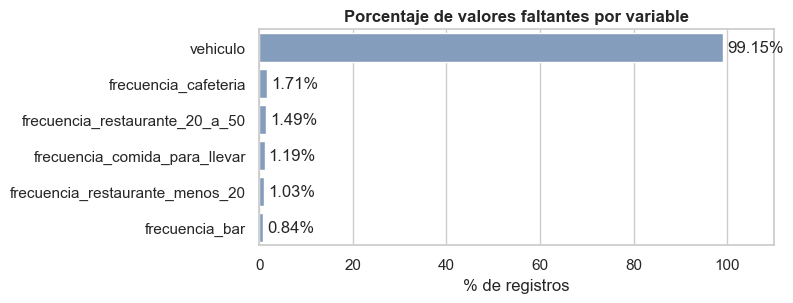

vehiculo diligenciado en 108 de 12664 registros (0.85%); tasa de aceptación en esos registros: 57.41%

Registros con al menos una frecuencia faltante: 605 (4.78%)
Tasa de aceptación  con faltante: 55.04% | sin faltante: 56.91%


In [5]:
# --- COMPLETITUD ---
faltantes = pd.DataFrame({"Faltantes": df_raw.isna().sum(), "% faltantes": (df_raw.isna().mean() * 100).round(2)})
faltantes = faltantes[faltantes["Faltantes"] > 0].sort_values("% faltantes", ascending=False)
display(faltantes)

fig, ax = plt.subplots(figsize=(8, 3.2))
sns.barplot(x=faltantes["% faltantes"], y=faltantes.index, color="#7a9cc6", ax=ax)
for i, v in enumerate(faltantes["% faltantes"]):
    ax.text(v + 0.8, i, f"{v:.2f}%", va="center")
ax.set(title="Porcentaje de valores faltantes por variable", xlabel="% de registros", ylabel="", xlim=(0, 110))
plt.tight_layout(); plt.show()

# ¿Qué es `vehiculo`? Solo 108 registros la tienen diligenciada
con_veh = df_raw[df_raw["vehiculo"].notna()]
print(f"vehiculo diligenciado en {len(con_veh)} de {len(df_raw)} registros "
      f"({len(con_veh)/len(df_raw):.2%}); tasa de aceptación en esos registros: {(con_veh.acepta_cupon=='Sí').mean():.2%}")

# ¿Los faltantes en las frecuencias de consumo se relacionan con la variable objetivo? (si no, imputar es poco riesgoso)
cols_frec = [c for c in df_raw.columns if c.startswith("frecuencia_")]
con_falt = df_raw[cols_frec].isna().any(axis=1)
print(f"\nRegistros con al menos una frecuencia faltante: {con_falt.sum()} ({con_falt.mean():.2%})")
print("Tasa de aceptación  con faltante: {:.2%} | sin faltante: {:.2%}".format(
      (df_raw.loc[con_falt, 'acepta_cupon'] == 'Sí').mean(), (df_raw.loc[~con_falt, 'acepta_cupon'] == 'Sí').mean()))

## 1.5 Unicidad: registros duplicados

In [6]:
# --- UNICIDAD ---
columnas_x = [c for c in df_raw.columns if c != "acepta_cupon"]
n_dup_exactos = df_raw.duplicated().sum()
n_dup_features = df_raw.duplicated(columnas_x).sum()
print(f"Filas duplicadas exactas (incluyendo la etiqueta): {n_dup_exactos}")
print(f"Filas con las mismas variables predictoras que otra fila: {n_dup_features}")

# Grupos de registros con idénticas variables predictoras pero etiquetas distintas (ruido irreducible)
grupos = df_raw[df_raw.duplicated(columnas_x, keep=False)].groupby(columnas_x, dropna=False)["acepta_cupon"].nunique()
print(f"Grupos con predictores idénticos: {len(grupos)}; de ellos con etiquetas contradictorias: {(grupos > 1).sum()}")

# Se eliminan solo los duplicados exactos
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"\nDimensiones antes: {df_raw.shape}  →  después de eliminar duplicados exactos: {df.shape}")

Filas duplicadas exactas (incluyendo la etiqueta): 74
Filas con las mismas variables predictoras que otra fila: 97
Grupos con predictores idénticos: 97; de ellos con etiquetas contradictorias: 23

Dimensiones antes: (12664, 26)  →  después de eliminar duplicados exactos: (12590, 26)


## 1.6 Valores atípicos

Temperatura (única variable numérica):


temperatura,30,55,80
registros,2304,3826,6460


,Variable,Categoría,Registros,% del total
3,ocupacion,"Agricultura, Pesca y Silvicultura",43,0.34
2,ocupacion,Limpieza y Mantenimiento de Edificios,44,0.35
0,educacion,Bachillerato incompleto,88,0.70
1,ocupacion,Producción,108,0.86


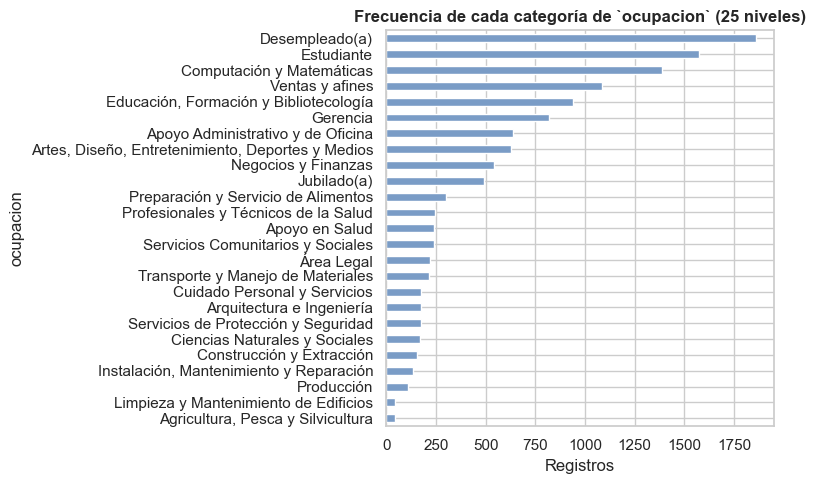

In [7]:
# --- VALORES ATÍPICOS ---
print("Temperatura (única variable numérica):")
display(df["temperatura"].value_counts().sort_index().to_frame("registros").T)

# Atípicos "categóricos": categorías muy poco frecuentes (<1 % de los registros)
raras = []
for col in df.select_dtypes(exclude="number").columns:
    if col in ("vehiculo", "acepta_cupon"):
        continue
    frec = df[col].value_counts(normalize=True)
    for cat, p in frec[frec < 0.01].items():
        raras.append({"Variable": col, "Categoría": cat, "Registros": int((df[col] == cat).sum()), "% del total": round(p * 100, 2)})
display(pd.DataFrame(raras).sort_values("% del total"))

fig, ax = plt.subplots(figsize=(8, 5))
df["ocupacion"].value_counts().sort_values().plot.barh(color="#7a9cc6", ax=ax)
ax.set(title="Frecuencia de cada categoría de `ocupacion` (25 niveles)", xlabel="Registros")
plt.tight_layout(); plt.show()

## 1.7 Análisis por subconjunto y distribución de `acepta_cupon`

,Registros,No acepta,Sí acepta,% No acepta,% Sí acepta,Razón clase mayoritaria / minoritaria
Cafetería,3979.0,1996.0,1983.0,50.16,49.84,1.01
Restaurante(<20),2769.0,810.0,1959.0,29.25,70.75,2.42


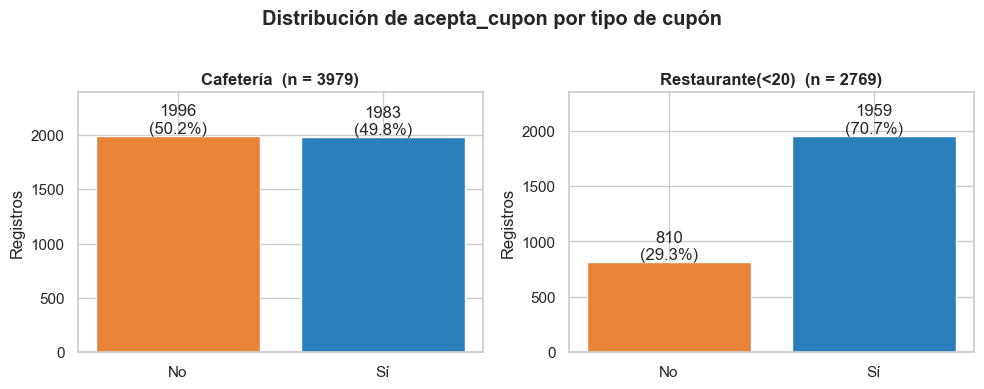

Cafetería: 3979 registros | duplicados: 0 | faltantes en frecuencias: 180 registros
Restaurante(<20): 2769 registros | duplicados: 0 | faltantes en frecuencias: 133 registros


In [8]:
CUPONES = ["Cafetería", "Restaurante(<20)"]
SUB = {c: df[df["cupon"] == c].copy() for c in CUPONES}

# Distribución de acepta_cupon por subconjunto
dist = pd.DataFrame({
    c: {"Registros": len(s),
        "No acepta": int((s.acepta_cupon == "No").sum()), "Sí acepta": int((s.acepta_cupon == "Sí").sum()),
        "% No acepta": round((s.acepta_cupon == "No").mean() * 100, 2), "% Sí acepta": round((s.acepta_cupon == "Sí").mean() * 100, 2),
        "Razón clase mayoritaria / minoritaria": round(s.acepta_cupon.value_counts().max() / s.acepta_cupon.value_counts().min(), 2)}
    for c, s in SUB.items()}).T
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (c, s) in zip(axes, SUB.items()):
    conteo = s.acepta_cupon.value_counts().reindex(["No", "Sí"])
    ax.bar(conteo.index, conteo.values, color=[COLOR_NO, COLOR_SI])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 25, f"{v}\n({v/len(s):.1%})", ha="center")
    ax.set(title=f"{c}  (n = {len(s)})", ylabel="Registros", ylim=(0, conteo.max() * 1.2))
plt.suptitle("Distribución de acepta_cupon por tipo de cupón", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

# Calidad por subconjunto
for c, s in SUB.items():
    print(f"{c}: {len(s)} registros | duplicados: {s.duplicated().sum()} | "
          f"faltantes en frecuencias: {s[[x for x in s.columns if x.startswith('frecuencia_')]].isna().any(axis=1).sum()} registros")

## 1.8 Relación exploratoria entre las variables y la aceptación

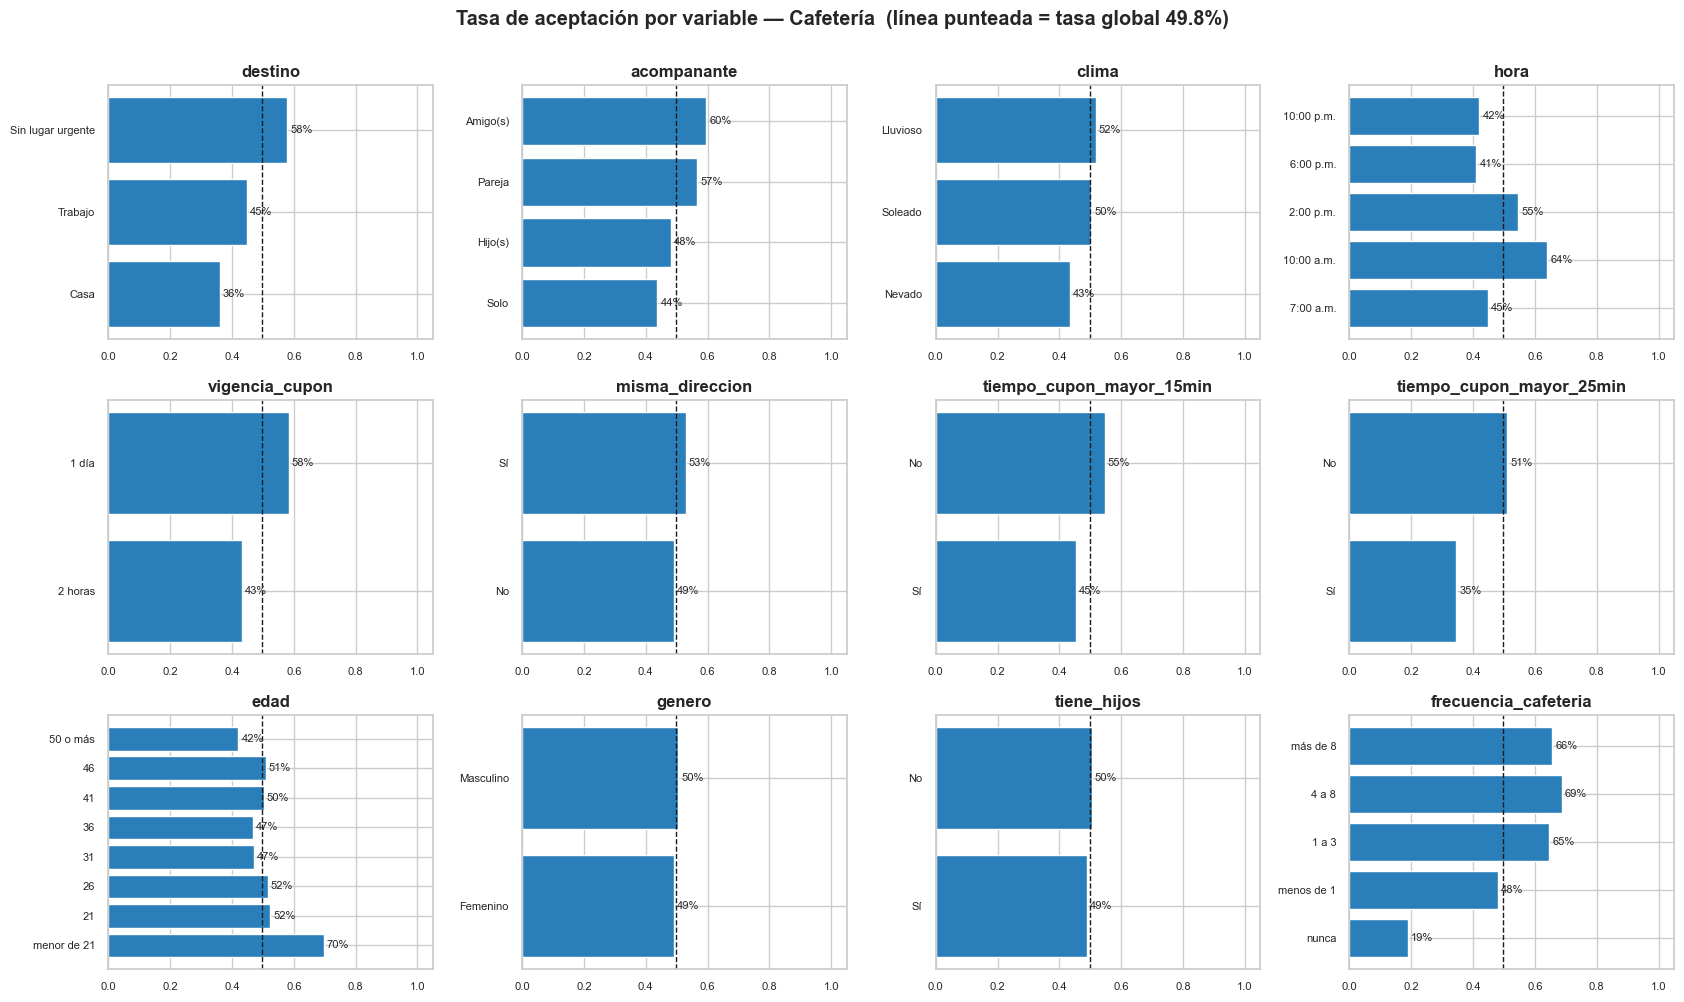

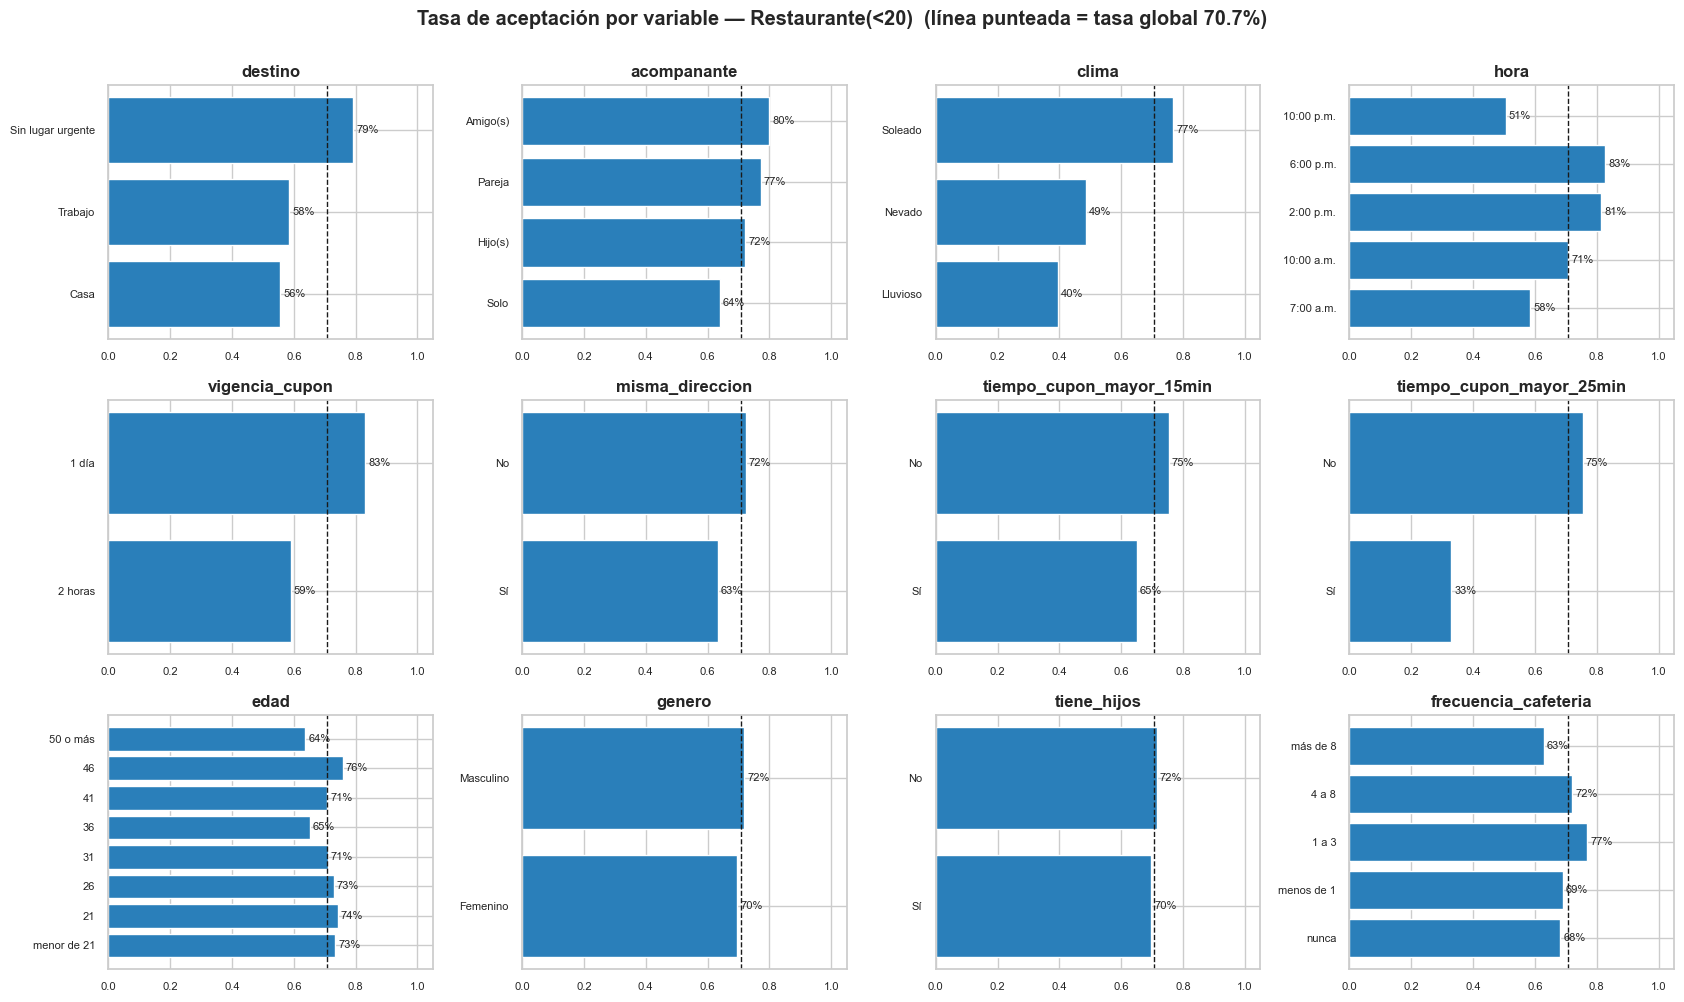

In [9]:
# Tasa de aceptación según cada variable de contexto/perfil, por subconjunto
vars_plot = ["destino", "acompanante", "clima", "hora", "vigencia_cupon", "misma_direccion",
             "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min", "edad", "genero", "tiene_hijos", "frecuencia_cafeteria"]
orden_hora = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
orden_edad = ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"]
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

for c, s in SUB.items():
    base = (s.acepta_cupon == "Sí").mean()
    fig, axes = plt.subplots(3, 4, figsize=(17, 10))
    for ax, v in zip(axes.ravel(), vars_plot):
        tasa = s.groupby(v)["acepta_cupon"].apply(lambda x: (x == "Sí").mean())
        orden = {"hora": orden_hora, "edad": orden_edad, "frecuencia_cafeteria": orden_frec}.get(v)
        tasa = tasa.reindex(orden) if orden else tasa.sort_values()
        ax.barh(tasa.index.astype(str), tasa.values, color=COLOR_SI)
        ax.axvline(base, color="k", ls="--", lw=1)
        for i, val in enumerate(tasa.values):
            ax.text(val + 0.01, i, f"{val:.0%}", va="center", fontsize=8)
        ax.set(title=v, xlim=(0, 1.05)); ax.tick_params(labelsize=8)
    plt.suptitle(f"Tasa de aceptación por variable — {c}  (línea punteada = tasa global {base:.1%})", fontweight="bold", y=1.0)
    plt.tight_layout(); plt.show()

## 1.9 Asociación con la variable objetivo y redundancia entre predictores

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.377,0.085
destino,0.183,0.236
hora,0.177,0.281
vigencia_cupon,0.150,0.264
ocupacion,0.149,0.107
acompanante,0.143,0.157
ingreso,0.117,0.098
edad,0.097,0.069
tiempo_cupon_mayor_15min,0.092,0.111
tiempo_cupon_mayor_25min,0.088,0.293


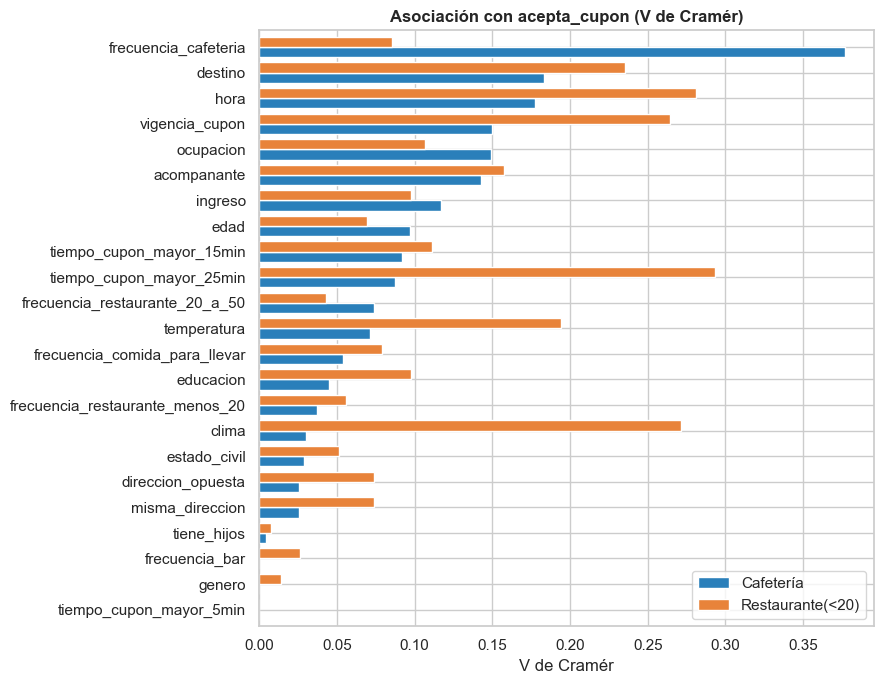

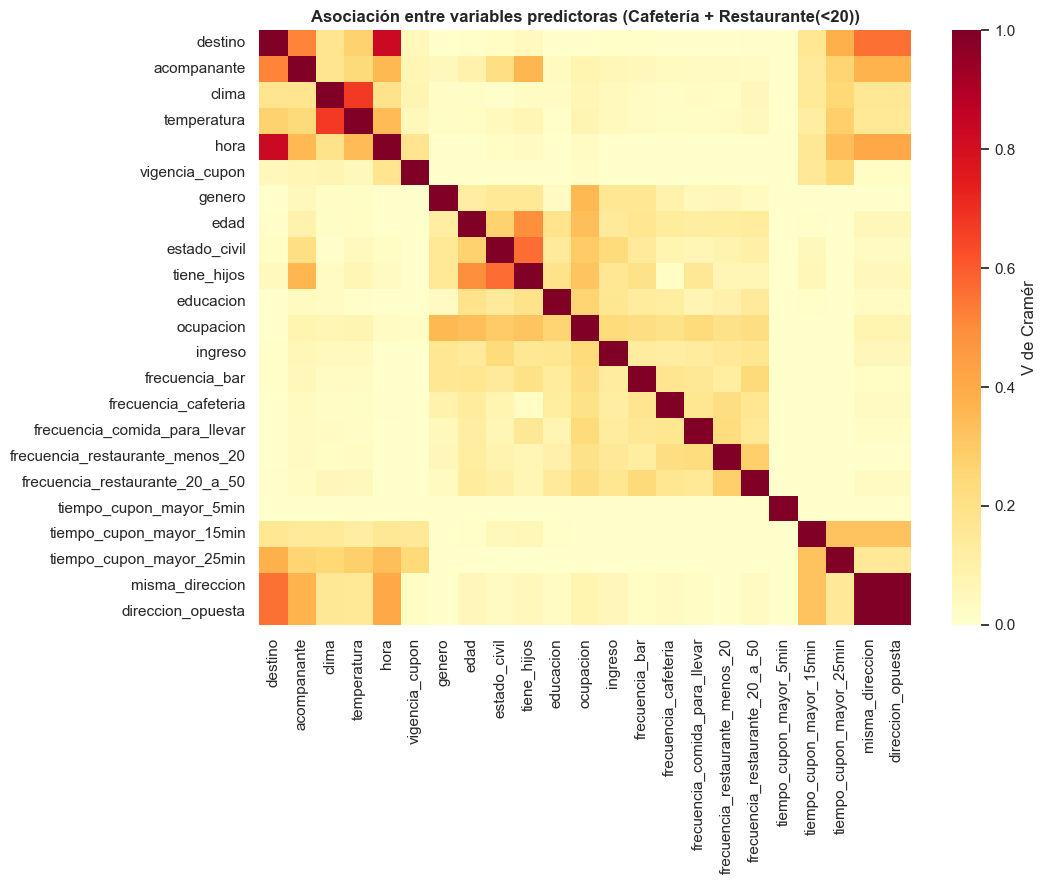

Pares de predictores más asociados:


V de Cramér
misma_direccion direccion_opuesta        1.000
destino         hora                     0.832
clima           temperatura              0.673
estado_civil    tiene_hijos              0.566
destino         direccion_opuesta        0.558
                misma_direccion          0.558
                acompanante              0.518
edad            tiene_hijos              0.493
hora            direccion_opuesta        0.409
                misma_direccion          0.409

In [10]:
# --- Asociación entre variables (V de Cramér, con corrección de sesgo) ---
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    if min(tabla.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum(); r, k = tabla.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))

# (a) Asociación de cada variable con la aceptación, para cada cupón
predictoras = [c for c in df.columns if c not in ("acepta_cupon", "cupon", "vehiculo")]
assoc = pd.DataFrame({c: {v: cramers_v(s[v], s["acepta_cupon"]) for v in predictoras} for c, s in SUB.items()})
assoc = assoc.sort_values("Cafetería", ascending=False)
display(assoc.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
assoc.sort_values("Cafetería").plot.barh(ax=ax, color=[COLOR_SI, COLOR_NO], width=0.8)
ax.set(title="Asociación con acepta_cupon (V de Cramér)", xlabel="V de Cramér")
plt.tight_layout(); plt.show()

# (b) Redundancia entre predictores (sobre los dos subconjuntos juntos)
conjunto = df[df.cupon.isin(CUPONES)]
cols_red = [c for c in predictoras]
M = pd.DataFrame(np.eye(len(cols_red)), index=cols_red, columns=cols_red)
for i, a in enumerate(cols_red):
    for b in cols_red[i + 1:]:
        M.loc[a, b] = M.loc[b, a] = cramers_v(conjunto[a], conjunto[b])

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(M, cmap="YlOrRd", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "V de Cramér"})
ax.set_title("Asociación entre variables predictoras (Cafetería + Restaurante(<20))")
plt.tight_layout(); plt.show()

pares = (M.where(np.triu(np.ones(M.shape), 1).astype(bool)).stack().rename("V de Cramér").sort_values(ascending=False))
print("Pares de predictores más asociados:")
display(pares.head(10).round(3).to_frame())

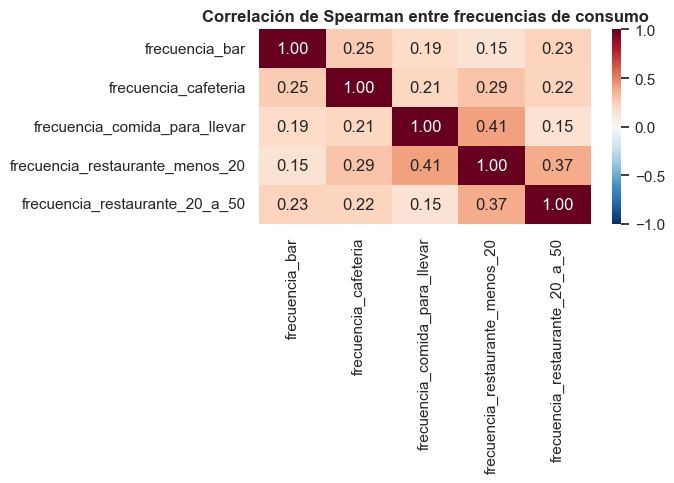

In [11]:
# Correlación (Spearman) entre las 5 frecuencias de consumo, que son ordinales
orden_frec = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
cols_frec = [c for c in df.columns if c.startswith("frecuencia_")]
codigos = df[cols_frec].apply(lambda s: s.map({v: i for i, v in enumerate(orden_frec)}))
corr = codigos.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman entre frecuencias de consumo")
plt.tight_layout(); plt.show()

### Conclusiones de la exploración

**Estructura.** 12.664 registros y 26 variables; el subconjunto **Cafetería** tiene 3.979 registros y **Restaurante(<20)** 2.769 (tras eliminar duplicados).

**Validez.** Los valores coinciden con el diccionario salvo en `vehiculo` (la categoría «Carro muy viejo para instalarle Onstar :D» no coincide con el diccionario). Hay además una **diferencia de formato** relevante: el diccionario escribe los rangos de `ingreso` sin espacios (`$12.500-$24.999`) y los datos con espacios (`$12.500 - $24.999`). Si se copia el orden desde el diccionario, el codificador ordinal no reconoce 7 de las 9 categorías (≈78 % de los registros) y las marca como "desconocidas" sin lanzar error. Por eso en la sección 2 se escriben las categorías tal como aparecen en los datos y se verifica con un `assert`.

**Consistencia.** Se cumplen todas las reglas verificadas, pero revelan redundancia: `misma_direccion` y `direccion_opuesta` son complementarias (V de Cramér = 1,00), `tiempo_cupon_mayor_5min` es constante, `tiempo_cupon_mayor_25min = Sí` implica `tiempo_cupon_mayor_15min = Sí`, y `clima` determina casi por completo `temperatura` (Nevado → 30 °F, Lluvioso → 55 °F; V = 0,67).

**Completitud.** `vehiculo` tiene 99,15 % de faltantes (solo 108 registros): inutilizable. Las cinco variables de frecuencia de consumo tienen entre 0,84 % y 1,71 % de faltantes (4,78 % de los registros tiene al menos uno). La tasa de aceptación de esos registros (55,0 %) es casi igual a la del resto (56,9 %), por lo que los faltantes no parecen informativos y la imputación es de bajo riesgo.

**Unicidad.** 74 registros son duplicados exactos y se eliminan: no aportan información nueva y, si quedaran repartidos entre entrenamiento y validación, inflarían el desempeño. Además, hay 97 registros con predictores idénticos a otro, de los cuales 23 grupos tienen **etiquetas contradictorias** (ruido irreducible que limita el desempeño máximo alcanzable); estos no se eliminan porque no son errores, sino respuestas distintas ante el mismo escenario.

**Valores atípicos.** La única variable numérica (`temperatura`) toma solo los valores de diseño 30, 55 y 80 °F: no hay atípicos numéricos. Los "atípicos" son categorías poco frecuentes (p. ej., `Bachillerato incompleto`, `Viudo(a)` y varias ocupaciones con menos de 1 % de los registros). Se conservan, porque son valores válidos, y se maneja su baja frecuencia con `handle_unknown="ignore"` y con regularización / hojas mínimas.

**Variable objetivo.** Cafetería está **balanceada** (50,2 % No / 49,8 % Sí); Restaurante(<20) está **desbalanceado** (29,3 % No / 70,7 % Sí; razón 2,42 : 1). La **clase minoritaria** de Restaurante(<20) es **«No acepta»**, por lo que además de F1 se reportará el recall de esa clase.

**Relación con la aceptación.** En Cafetería la asociación dominante es `frecuencia_cafeteria` (V = 0,38; quienes "nunca" van a cafeterías aceptan 19 % frente a 65-69 % de quienes van con frecuencia); también influyen `vigencia_cupon` (58 % a 1 día vs 43 % a 2 horas) y `destino` (58 % «sin lugar urgente» vs 36 % «casa»). En Restaurante(<20) pesa más el **contexto**: `tiempo_cupon_mayor_25min` (V = 0,29; 33 % de aceptación si el local está a más de 25 min vs 75 %), `hora` (0,28), `clima` (0,27; 77 % soleado vs 40 % lluvioso), `vigencia_cupon` (0,26; 83 % vs 59 %) y `destino`.

**Redundancia entre predictores.** Además de los pares ya citados, `destino`–`hora` están muy asociadas (V = 0,83: el destino «trabajo» ocurre en la mañana y «casa» en la tarde), `estado_civil`–`tiene_hijos` (0,57) y `destino`–`acompanante` (0,52).

# 2. Propuesta de limpieza y preparación de los datos

Cada decisión se deriva de un hallazgo de la exploración:

| # | Hallazgo | Decisión | Justificación |
|:-:|:--|:--|:--|
| 1 | 74 duplicados exactos | **Eliminarlos** (ya hecho en 1.5) | Evitan sobreponderar observaciones y fugas entre particiones de validación. |
| 2 | 23 grupos con predictores idénticos y etiqueta contradictoria | **Conservarlos** | Son respuestas legítimas; se documentan como ruido que limita el techo del desempeño. |
| 3 | `vehiculo` con 99,15 % de faltantes | **Descartar la variable** | Con 108 valores no se puede imputar ni aprender de ella; imputar crearía información inventada. |
| 4 | `tiempo_cupon_mayor_5min` constante | **Descartar** | Varianza cero: no discrimina. |
| 5 | `direccion_opuesta` = complemento de `misma_direccion` | **Descartar `direccion_opuesta`** | Redundancia exacta; duplicaría el efecto en la regresión logística (colinealidad perfecta). |
| 6 | `cupon` | **Usarla solo para dividir los datos y descartarla como predictor** | Es constante dentro de cada subconjunto. |
| 7 | Faltantes < 2 % en las 5 frecuencias | **Imputar con la moda dentro del pipeline** | Pérdida mínima de información, faltantes no informativos (aceptación 55,0 % vs 56,9 %); ajustar la moda solo con datos de entrenamiento evita fuga. |
| 8 | Variables ordinales (`hora`, `edad`, `educacion`, `ingreso`, 5 frecuencias) | **Codificación ordinal** respetando el orden del diccionario | Conserva el orden y evita multiplicar columnas. Se verifica con `assert` que todas las categorías estén reconocidas (por el problema de formato de `ingreso`). |
| 9 | Variables nominales (`destino`, `acompanante`, `clima`, `ocupacion`, etc.) | **One-Hot** (`drop="if_binary"`, `handle_unknown="ignore"`) | No hay orden entre categorías; las binarias usan una sola columna. |
| 10 | `temperatura` numérica (3 valores) | **Conservar**; estandarizar solo para regresión logística | Aporta información pese a su relación con `clima`; la regularización L2/L1 maneja la colinealidad parcial. |
| 11 | Regresión logística sensible a la escala | **Estandarizar numéricas y ordinales** solo en ese modelo | Sin esto la penalización afectaría de forma desigual a variables en escalas distintas. Árboles y Random Forest son invariantes a la escala. |
| 12 | Desbalance en Restaurante(<20) | **No balancear de entrada**; evaluar SMOTE en el punto 6 | La decisión se toma con evidencia (F1 y recall de la clase minoritaria). |

**Partición y control de fuga.** Para cada cupón se hace una partición estratificada 80 % entrenamiento / 20 % prueba (`random_state=42`), que conserva la proporción de clases. Toda transformación (imputación, escalado, codificación y, después, SMOTE) está **dentro de un `Pipeline`**, de modo que se ajusta únicamente con los datos de entrenamiento de cada partición de validación cruzada. El conjunto de prueba solo se usa para la evaluación final.

In [12]:
# Orden de las variables ordinales (según el diccionario de datos). Se escribe EXACTAMENTE como aparece en los datos.
ORD = {
    "hora": ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."],
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999", "$50.000 - $62.499",
                "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999", "$100.000 o más"],
}
for c in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
          "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]:
    ORD[c] = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]

# CONTROL DE CALIDAD: toda categoría observada (entrenamiento y prueba) debe estar en el orden definido.
# Si no, OrdinalEncoder la codificaría como "desconocida" y se perdería información en silencio.
for nombre, base in {"entrenamiento": df, "prueba": datos_prueba}.items():
    for col, orden in ORD.items():
        no_reconocidos = set(base[col].dropna().unique()) - set(orden)
        assert not no_reconocidos, f"[{nombre}] {col}: categorías fuera del orden definido: {no_reconocidos}"
print(" Todas las categorías ordinales observadas coinciden con el orden definido (entrenamiento y prueba).")

# Variables que se descartan y razón
DESCARTAR = {
    "cupon": "constante dentro de cada subconjunto (se usa para dividir los datos)",
    "vehiculo": "99,1 % de faltantes (solo 108 registros)",
    "tiempo_cupon_mayor_5min": "constante ('Sí' en todos los registros): varianza cero",
    "direccion_opuesta": "complemento exacto de misma_direccion (redundante)",
}
display(pd.Series(DESCARTAR, name="Motivo").to_frame())

 Todas las categorías ordinales observadas coinciden con el orden definido (entrenamiento y prueba).


,Motivo
cupon,constante dentro de cada subconjunto (se usa para dividir los datos)
vehiculo,"99,1 % de faltantes (solo 108 registros)"
tiempo_cupon_mayor_5min,constante ('Sí' en todos los registros): varianza cero
direccion_opuesta,complemento exacto de misma_direccion (redundante)


In [13]:
# Construcción de X, y y partición estratificada 80/20 por tipo de cupón
DATOS = {}
for cupon, sub in SUB.items():
    sub = sub.drop(columns=list(DESCARTAR))
    X = sub.drop(columns="acepta_cupon")
    y = (sub["acepta_cupon"] == "Sí").astype(int)           # 1 = Sí acepta, 0 = No acepta (clase minoritaria en Restaurante)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
    DATOS[cupon] = dict(X_all=X, y_all=y, X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test)

COLS_NUM = ["temperatura"]
COLS_ORD = [c for c in ORD if c in X.columns]
COLS_NOM = [c for c in X.columns if c not in COLS_NUM + COLS_ORD]
COLUMNAS_MODELO = list(X.columns)
print("Variables predictoras:", len(COLUMNAS_MODELO))
print("  numéricas :", COLS_NUM)
print("  ordinales :", COLS_ORD)
print("  nominales :", COLS_NOM)

resumen_split = pd.DataFrame({
    c: {"Train": len(d["X_train"]), "Test": len(d["X_test"]),
        "% Sí en train": round(d["y_train"].mean() * 100, 1), "% Sí en test": round(d["y_test"].mean() * 100, 1)}
    for c, d in DATOS.items()}).T
display(resumen_split)

Variables predictoras: 21
  numéricas : ['temperatura']
  ordinales : ['hora', 'edad', 'educacion', 'ingreso', 'frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar', 'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50']
  nominales : ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero', 'estado_civil', 'tiene_hijos', 'ocupacion', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion']


,Train,Test,% Sí en train,% Sí en test
Cafetería,3183.0,796.0,49.8,49.9
Restaurante(<20),2215.0,554.0,70.7,70.8


In [14]:
def construir_preprocesador(escalar):
    """ColumnTransformer: imputación + codificación (+ estandarización si `escalar`).
    - Regresión logística: escalar=True  (la regularización es sensible a la escala de las variables).
    - Árboles / Random Forest: escalar=False (invariantes a transformaciones monótonas)."""
    pasos_ord = [("imputar", SimpleImputer(strategy="most_frequent")),
                 ("codificar", OrdinalEncoder(categories=[ORD[c] for c in COLS_ORD]))]
    if escalar:
        pasos_ord.append(("escalar", StandardScaler()))
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", COLS_NUM),
        ("ord", Pipeline(pasos_ord), COLS_ORD),
        ("nom", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("codificar", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), COLS_NOM),
    ], sparse_threshold=0)

# Ejemplo: dimensión de la matriz transformada y nombres de las columnas
prep_demo = construir_preprocesador(escalar=True).fit(DATOS["Cafetería"]["X_train"])
nombres_demo = prep_demo.get_feature_names_out()
print("Columnas originales:", len(COLUMNAS_MODELO), "→ columnas tras la transformación:", len(nombres_demo))
print("Las 5 variables que más columnas generan (por One-Hot):")
display(pd.Series([re.sub(r"^(num|ord|nom)__", "", n) for n in nombres_demo]).str.replace(r"_[^_]*$", "", regex=True).value_counts().head(5).to_frame("columnas"))

Columnas originales: 21 → columnas tras la transformación: 56
Las 5 variables que más columnas generan (por One-Hot):


,columnas
ocupacion,25
estado_civil,5
acompanante,4
destino,3
clima,3


**Resultado.** Se obtienen 21 variables predictoras (1 numérica, 9 ordinales, 11 nominales) que, tras One-Hot, se transforman en una matriz de mayor dimensión; `ocupacion` (25 niveles) es la que más columnas genera. Las particiones conservan la proporción de clases (49,8 % / 49,9 % de «Sí» en Cafetería y 70,7 % / 70,8 % en Restaurante(<20)).

# 3. Modelos de regresión logística

**Diseño.** Un `Pipeline` (preprocesamiento con estandarización → `LogisticRegression`) por cupón, con `GridSearchCV` y validación cruzada estratificada de 5 particiones. La métrica de selección es el **F1** de la clase positiva. Se exploran: tipo de regularización (`l1`, `l2`, `elasticnet`), **solver** (`liblinear`, `lbfgs`, `saga`; cada uno admite solo ciertas penalizaciones, por eso la rejilla se define como lista de diccionarios) y el parámetro de regularización `C` ∈ {0,001 … 100}. Las funciones auxiliares definidas abajo se reutilizan en los puntos 4, 5 y 6.

In [15]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
RES = {}          # RES[(modelo, cupon)] -> resultados de la búsqueda y métricas en test

def metricas_completas(y, p):
    """Métricas para ambas clases. 'Sí' = clase positiva (1); 'No' = clase 0 (minoritaria en Restaurante(<20))."""
    return {
        "Precisión (Sí)": precision_score(y, p, pos_label=1, zero_division=0),
        "Recall (Sí)":    recall_score(y, p, pos_label=1, zero_division=0),
        "F1 (Sí)":        f1_score(y, p, pos_label=1, zero_division=0),
        "Precisión (No)": precision_score(y, p, pos_label=0, zero_division=0),
        "Recall (No)":    recall_score(y, p, pos_label=0, zero_division=0),
        "F1 (No)":        f1_score(y, p, pos_label=0, zero_division=0),
        "F1 macro":       f1_score(y, p, average="macro", zero_division=0),
        "Accuracy":       accuracy_score(y, p),
    }

def entrenar_y_evaluar(nombre, cupon, pipeline, grid):
    d = DATOS[cupon]
    gs = GridSearchCV(pipeline, grid, scoring="f1", cv=CV, n_jobs=-1, refit=True, error_score="raise")
    gs.fit(d["X_train"], d["y_train"])
    pred = gs.predict(d["X_test"])
    m = metricas_completas(d["y_test"], pred)
    m["F1 CV (train)"]  = gs.best_score_
    m["Desv. F1 CV"]    = gs.cv_results_["std_test_score"][gs.best_index_]
    m["F1 train"]       = f1_score(d["y_train"], gs.predict(d["X_train"]))
    RES[(nombre, cupon)] = dict(busqueda=gs, pred=pred, metricas=m)

    print("=" * 78); print(f"{nombre.upper()} — {cupon}"); print("=" * 78)
    print("Combinaciones evaluadas:", len(gs.cv_results_["params"]), "× 5 particiones")
    print("Mejores hiperparámetros:", {k.split('__')[1]: v for k, v in gs.best_params_.items()})
    print(f"F1 en validación cruzada: {gs.best_score_:.4f} (± {m['Desv. F1 CV']:.4f}) | F1 en entrenamiento: {m['F1 train']:.4f} | F1 en test: {m['F1 (Sí)']:.4f}")
    print("\nReporte de clasificación en test:")
    print(classification_report(d["y_test"], pred, target_names=["No acepta", "Sí acepta"], digits=3, zero_division=0))
    return gs

def top_configuraciones(nombre, cupon, k=5):
    r = pd.DataFrame(RES[(nombre, cupon)]["busqueda"].cv_results_).sort_values("rank_test_score").head(k)
    out = r[["params", "mean_test_score", "std_test_score"]].copy()
    out["params"] = out["params"].apply(lambda p: {k_.split("__")[1]: v for k_, v in p.items()})
    return out.rename(columns={"params": "Hiperparámetros", "mean_test_score": "F1 CV medio", "std_test_score": "Desv."}).round(4)

def sensibilidad(nombre, cupon, parametros):
    """Mejor F1 de CV obtenido para cada valor de un hiperparámetro (muestra cuáles influyen)."""
    r = pd.DataFrame(RES[(nombre, cupon)]["busqueda"].cv_results_)
    cols = ["param_clf__" + p for p in parametros]
    return r.assign(**{c: r[c].astype(str) for c in cols}).groupby(cols)["mean_test_score"].max().round(4)

def matrices_confusion(nombre):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
    for ax, cupon in zip(axes, CUPONES):
        d = DATOS[cupon]
        ConfusionMatrixDisplay.from_predictions(d["y_test"], RES[(nombre, cupon)]["pred"], display_labels=["No", "Sí"],
                                                cmap="Blues", colorbar=False, ax=ax)
        ax.set_title(f"{cupon}"); ax.grid(False)
    plt.suptitle(f"Matrices de confusión en test — {nombre}", fontweight="bold")
    plt.tight_layout(); plt.show()

In [16]:
NOMBRE_LR = "Regresión logística"
grid_lr = [
    {"clf__solver": ["liblinear"], "clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf__solver": ["lbfgs"],     "clf__penalty": ["l2"],       "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf__solver": ["saga"],      "clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    {"clf__solver": ["saga"],      "clf__penalty": ["elasticnet"], "clf__l1_ratio": [0.5], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100]},
]
for cupon in CUPONES:
    pipe = Pipeline([("prep", construir_preprocesador(escalar=True)),
                     ("clf", LogisticRegression(max_iter=5000, random_state=SEED))])
    entrenar_y_evaluar(NOMBRE_LR, cupon, pipe, grid_lr)

REGRESIÓN LOGÍSTICA — Cafetería
Combinaciones evaluadas: 36 × 5 particiones
Mejores hiperparámetros: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
F1 en validación cruzada: 0.7087 (± 0.0243) | F1 en entrenamiento: 0.7199 | F1 en test: 0.6909

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.693     0.684     0.689       399
   Sí acepta      0.687     0.695     0.691       397

    accuracy                          0.690       796
   macro avg      0.690     0.690     0.690       796
weighted avg      0.690     0.690     0.690       796

REGRESIÓN LOGÍSTICA — Restaurante(<20)
Combinaciones evaluadas: 36 × 5 particiones
Mejores hiperparámetros: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
F1 en validación cruzada: 0.8472 (± 0.0063) | F1 en entrenamiento: 0.8483 | F1 en test: 0.8378

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.629     0.346     0.446    


### Cafetería: mejor F1 de CV por combinación solver / regularización


F1 CV (mejor C)
param_clf__solver param_clf__penalty                 
lbfgs             l2                           0.7078
liblinear         l1                           0.7073
                  l2                           0.7087
saga              elasticnet                   0.7074
                  l1                           0.7056
                  l2                           0.7080

Top-5 configuraciones — Cafetería


,Hiperparámetros,F1 CV medio,Desv.
5,"{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}",0.7087,0.0243
23,"{'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}",0.7080,0.0248
14,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.7078,0.0251
33,"{'C': 1, 'l1_ratio': 0.5, 'penalty': 'elasticnet', 'solver': 'saga'}",0.7074,0.0198
6,"{'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}",0.7073,0.0222



### Restaurante(<20): mejor F1 de CV por combinación solver / regularización


F1 CV (mejor C)
param_clf__solver param_clf__penalty                 
lbfgs             l2                           0.8470
liblinear         l1                           0.8453
                  l2                           0.8472
saga              elasticnet                   0.8453
                  l1                           0.8434
                  l2                           0.8470

Top-5 configuraciones — Restaurante(<20)


,Hiperparámetros,F1 CV medio,Desv.
5,"{'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}",0.8472,0.0063
14,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.8470,0.0067
23,"{'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}",0.8470,0.0067
2,"{'C': 0.01, 'penalty': 'l1', 'solver': 'liblinear'}",0.8453,0.0068
32,"{'C': 0.1, 'l1_ratio': 0.5, 'penalty': 'elasticnet', 'solver': 'saga'}",0.8453,0.0059


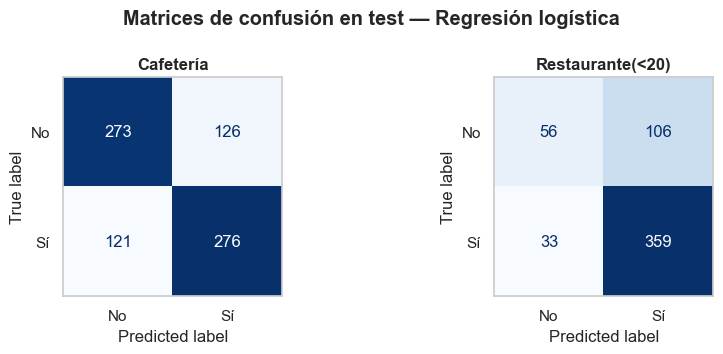

In [17]:
for cupon in CUPONES:
    print(f"\n### {cupon}: mejor F1 de CV por combinación solver / regularización")
    display(sensibilidad(NOMBRE_LR, cupon, ["solver", "penalty"]).to_frame("F1 CV (mejor C)"))
    print(f"Top-5 configuraciones — {cupon}")
    display(top_configuraciones(NOMBRE_LR, cupon))
matrices_confusion(NOMBRE_LR)

### Análisis — regresión logística

- **Cafetería:** `liblinear`, regularización **L2**, `C = 0,1`. F1 de validación cruzada 0,709 (± 0,024); F1 en test 0,691 (precisión 0,687; recall 0,695). El desempeño es equilibrado entre clases (recall de «No» 0,684 y de «Sí» 0,695), pero moderado: un modelo lineal captura solo parte de las interacciones entre contexto y hábitos.
- **Restaurante(<20):** también L2 con `C = 0,1`. F1 de CV 0,847 y F1 en test 0,838 (precisión 0,772; recall 0,916). Sin embargo, el **recall de «No acepta» es solo 0,346**: el modelo clasifica casi todo como «Sí», lo que produce un F1 alto en la clase mayoritaria sin detectar bien los rechazos.
- **Sobre la rejilla:** L2 con `C = 0,1` fue la mejor combinación en ambos cupones, pero las diferencias con L1, elasticnet y con los otros solvers son mínimas (F1 de CV entre 0,706 y 0,709 en Cafetería y entre 0,843 y 0,847 en Restaurante(<20)): cuando convergen, los solvers optimizan el mismo problema, así que la elección práctica es `liblinear` (el más rápido aquí). Una regularización moderada ayuda porque hay muchas columnas One-Hot (ocupación) y predictores correlacionados.
- Entrenamiento (0,720 / 0,848) y validación (0,709 / 0,847) son similares: el modelo no sobreajusta, pero tampoco captura más estructura (subajuste moderado en Cafetería).

# 4. Modelos de árboles de decisión

**Diseño.** `Pipeline` (preprocesamiento sin escalado → `DecisionTreeClassifier`) por cupón, con `GridSearchCV` (CV estratificada de 5 particiones, F1). Se exploran el **criterio de división** (`gini`, `entropy`, `log_loss`), la **profundidad máxima** (3, 5, 8, 12, sin límite) y el **mínimo de muestras por hoja** (1, 5, 10, 20): 60 combinaciones por cupón.

In [18]:
NOMBRE_DT = "Árbol de decisión"
grid_dt = {
    "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__max_depth": [3, 5, 8, 12, None],
    "clf__min_samples_leaf": [1, 5, 10, 20],
}
for cupon in CUPONES:
    pipe = Pipeline([("prep", construir_preprocesador(escalar=False)),
                     ("clf", DecisionTreeClassifier(random_state=SEED))])
    entrenar_y_evaluar(NOMBRE_DT, cupon, pipe, grid_dt)

ÁRBOL DE DECISIÓN — Cafetería
Combinaciones evaluadas: 60 × 5 particiones
Mejores hiperparámetros: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1}
F1 en validación cruzada: 0.7113 (± 0.0103) | F1 en entrenamiento: 0.7219 | F1 en test: 0.6882

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.691     0.672     0.681       399
   Sí acepta      0.679     0.698     0.688       397

    accuracy                          0.685       796
   macro avg      0.685     0.685     0.685       796
weighted avg      0.685     0.685     0.685       796

ÁRBOL DE DECISIÓN — Restaurante(<20)
Combinaciones evaluadas: 60 × 5 particiones
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10}
F1 en validación cruzada: 0.8429 (± 0.0043) | F1 en entrenamiento: 0.8388 | F1 en test: 0.8396

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.633    


### Cafetería: sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)


param_clf__criterion,entropy,gini,log_loss
F1 CV — criterion,0.7113,0.7107,0.7113


param_clf__max_depth,12,3,5,8
F1 CV — max_depth,0.6865,0.703,0.7113,0.6954


param_clf__min_samples_leaf,1,10,20,5
F1 CV — min_samples_leaf,0.7113,0.7095,0.71,0.7111


,Hiperparámetros,F1 CV medio,Desv.
24,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1}",0.7113,0.0103
44,"{'criterion': 'log_loss', 'max_depth': 5, 'min_samples_leaf': 1}",0.7113,0.0103
45,"{'criterion': 'log_loss', 'max_depth': 5, 'min_samples_leaf': 5}",0.7111,0.0096
25,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5}",0.7111,0.0096
5,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 5}",0.7107,0.0119



### Restaurante(<20): sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)


param_clf__criterion,entropy,gini,log_loss
F1 CV — criterion,0.8407,0.8429,0.8407


param_clf__max_depth,12,3,5,8
F1 CV — max_depth,0.84,0.8429,0.8418,0.8409


param_clf__min_samples_leaf,1,10,20,5
F1 CV — min_samples_leaf,0.8406,0.8429,0.8418,0.842


,Hiperparámetros,F1 CV medio,Desv.
2,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10}",0.8429,0.0043
1,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 5}",0.8420,0.0036
7,"{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 20}",0.8418,0.0089
11,"{'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 20}",0.8409,0.0080
22,"{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 10}",0.8407,0.0062


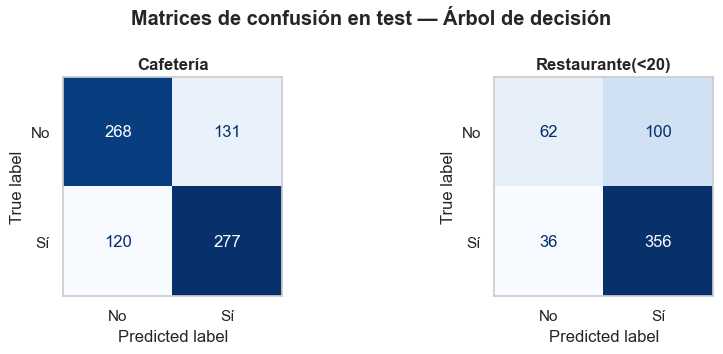

In [19]:
for cupon in CUPONES:
    print(f"\n### {cupon}: sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)")
    for p in ["criterion", "max_depth", "min_samples_leaf"]:
        display(sensibilidad(NOMBRE_DT, cupon, [p]).to_frame(f"F1 CV — {p}").T)
    display(top_configuraciones(NOMBRE_DT, cupon))
matrices_confusion(NOMBRE_DT)

### Análisis — árboles de decisión

- **Cafetería:** criterio `entropy`, profundidad 5, hoja mínima 1. F1 de CV 0,711 y F1 en test 0,688 (precisión 0,679; recall 0,698). Prácticamente igual a la regresión logística (0,691): el árbol poco profundo no mejora lo que logra un modelo lineal.
- **Restaurante(<20):** `gini`, profundidad **3**, hoja mínima 10. F1 de CV 0,843 y de test 0,840 (precisión 0,781; recall 0,908); recall de «No» 0,383, algo mejor que la regresión logística (0,346) pero todavía bajo.
- **Hiperparámetros.** En Cafetería, un árbol de profundidad 12 baja el F1 de CV a 0,687 frente a 0,711 con profundidad 5 (sobreajuste); en Restaurante(<20) el efecto es pequeño (0,840-0,843) y gana el árbol más simple (profundidad 3). El criterio de división es casi irrelevante (diferencias ≤ 0,002 entre `gini`, `entropy` y `log_loss`).
- **Utilidad:** el árbol es interpretable (reglas del punto 8). **Limitación:** es inestable (pequeños cambios en los datos pueden cambiar las ramas) y un solo árbol poco profundo no capta toda la complejidad.

# 5. Modelos de Random Forest

**Diseño.** `Pipeline` (preprocesamiento sin escalado → `RandomForestClassifier`) por cupón, con `GridSearchCV` (CV de 5 particiones, F1). Se exploran el **número de árboles** (100, 300), la **profundidad máxima** (10, 20, sin límite), el **mínimo de muestras por hoja** (1, 3, 5) y, adicionalmente, `max_features` (`sqrt`, 0,5): 36 combinaciones por cupón.

In [20]:
NOMBRE_RF = "Random Forest"
grid_rf = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [10, 20, None],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", 0.5],
}
def pipeline_rf():
    return Pipeline([("prep", construir_preprocesador(escalar=False)),
                     ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))])

for cupon in CUPONES:
    entrenar_y_evaluar(NOMBRE_RF, cupon, pipeline_rf(), grid_rf)

RANDOM FOREST — Cafetería
Combinaciones evaluadas: 36 × 5 particiones
Mejores hiperparámetros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
F1 en validación cruzada: 0.7628 (± 0.0109) | F1 en entrenamiento: 0.9991 | F1 en test: 0.7781

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.783     0.767     0.775       399
   Sí acepta      0.770     0.786     0.778       397

    accuracy                          0.776       796
   macro avg      0.776     0.776     0.776       796
weighted avg      0.777     0.776     0.776       796

RANDOM FOREST — Restaurante(<20)
Combinaciones evaluadas: 36 × 5 particiones
Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
F1 en validación cruzada: 0.8563 (± 0.0092) | F1 en entrenamiento: 0.9994 | F1 en test: 0.8514

Reporte de clasificación en test:
              precision    recall  f1-scor


### Cafetería: sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)


param_clf__n_estimators,100,300
F1 CV — n_estimators,0.7626,0.7628


param_clf__max_depth,10,20
F1 CV — max_depth,0.7491,0.7628


param_clf__min_samples_leaf,1,3,5
F1 CV — min_samples_leaf,0.7628,0.7536,0.7389


param_clf__max_features,0.5,sqrt
F1 CV — max_features,0.7568,0.7628


,Hiperparámetros,F1 CV medio,Desv.
13,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimato...",0.7628,0.0109
24,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estima...",0.7626,0.0161
12,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimato...",0.7599,0.0123
25,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estima...",0.7590,0.0102
19,"{'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators'...",0.7568,0.0099



### Restaurante(<20): sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)


param_clf__n_estimators,100,300
F1 CV — n_estimators,0.8563,0.8554


param_clf__max_depth,10,20
F1 CV — max_depth,0.8534,0.8554


param_clf__min_samples_leaf,1,3,5
F1 CV — min_samples_leaf,0.8563,0.8542,0.8518


param_clf__max_features,0.5,sqrt
F1 CV — max_features,0.8534,0.8563


,Hiperparámetros,F1 CV medio,Desv.
24,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estima...",0.8563,0.0092
13,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimato...",0.8554,0.0061
25,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estima...",0.8550,0.0050
15,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimato...",0.8542,0.0049
12,"{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimato...",0.8535,0.0052


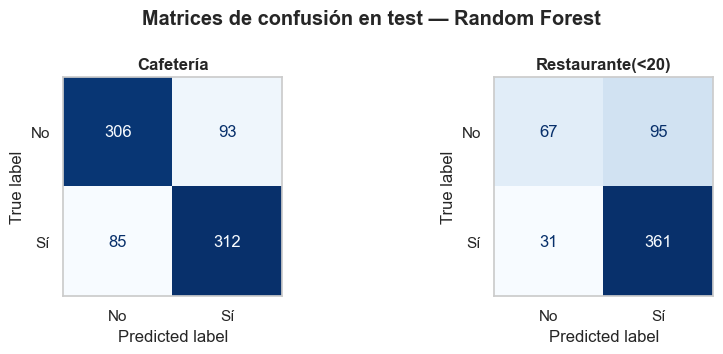

,Cupón,Modelo,F1 CV,F1 train,F1 test (Sí),Recall test (No),F1 macro test
0,Cafetería,Árbol de decisión,0.7113,0.7219,0.6882,0.6717,0.6846
1,Cafetería,Random Forest,0.7628,0.9991,0.7781,0.7669,0.7764
2,Restaurante(<20),Árbol de decisión,0.8429,0.8388,0.8396,0.3827,0.6583
3,Restaurante(<20),Random Forest,0.8563,0.9994,0.8514,0.4136,0.6834


In [21]:
for cupon in CUPONES:
    print(f"\n### {cupon}: sensibilidad a cada hiperparámetro (mejor F1 de CV por valor)")
    for p in ["n_estimators", "max_depth", "min_samples_leaf", "max_features"]:
        display(sensibilidad(NOMBRE_RF, cupon, [p]).to_frame(f"F1 CV — {p}").T)
    display(top_configuraciones(NOMBRE_RF, cupon))
matrices_confusion(NOMBRE_RF)

# Comparación Random Forest vs. árbol individual (mismas particiones de test)
comp = []
for cupon in CUPONES:
    for nombre in [NOMBRE_DT, NOMBRE_RF]:
        m = RES[(nombre, cupon)]["metricas"]
        comp.append({"Cupón": cupon, "Modelo": nombre, "F1 CV": m["F1 CV (train)"], "F1 train": m["F1 train"],
                     "F1 test (Sí)": m["F1 (Sí)"], "Recall test (No)": m["Recall (No)"], "F1 macro test": m["F1 macro"]})
comp = pd.DataFrame(comp)
display(comp.round(4))

### Análisis — Random Forest

- **Cafetería:** 300 árboles, profundidad 20, hoja mínima 1, `max_features="sqrt"`. F1 de CV 0,763 (± 0,011), **F1 en test 0,778** (precisión 0,770; recall 0,786), equilibrado entre clases (0,775 / 0,778).
- **Restaurante(<20):** 100 árboles, sin límite de profundidad, hoja mínima 1. F1 de CV 0,856 y **F1 en test 0,851** (precisión 0,792; recall 0,921); recall de «No» 0,414.
- **Comparación con el árbol individual.** El Random Forest supera al mejor árbol en ambos cupones: +0,090 de F1 en Cafetería (0,778 vs 0,688) y +0,011 en Restaurante(<20) (0,851 vs 0,840). Al promediar muchos árboles descorrelacionados (bootstrap + subconjunto aleatorio de variables) se reduce la varianza, y lo hace aceptando árboles profundos que individualmente sobreajustarían.
- **Sobreajuste aparente.** El F1 en entrenamiento es ≈ 0,999 frente a 0,76-0,86 en validación: es normal en un bosque con hojas de una muestra y no implica fallo, pues la selección se hizo con validación cruzada y el test confirma el valor de CV. En Cafetería, sin embargo, parte de la ventaja sobre los otros modelos depende de que haya escenarios del mismo conductor en entrenamiento y prueba (se analiza en el punto 7).

# 6. Balanceo de clases (SMOTE) en Restaurante(<20)

**¿Por qué el desbalance podría afectar?** Con 70,7 % de «Sí», un clasificador que optimiza el error global o el F1 de la clase positiva tiende a predecir «Sí», y el costo se paga en la clase minoritaria «No acepta» (en la regresión logística, recall de «No» = 0,346). SMOTE sintetiza ejemplos de la clase minoritaria por interpolación entre vecinos para que el modelo "vea" más rechazos.

**Diseño metodológico (sin fuga de información).**
- SMOTE está dentro de un `Pipeline` de **imbalanced-learn**: solo actúa en `fit`, es decir, únicamente sobre los datos de entrenamiento de cada partición de la validación cruzada, nunca sobre validación ni sobre test.
- Se compara con el Random Forest sin balancear usando la **misma rejilla**, la **misma CV** y el **mismo conjunto de test**.
- Se reportan precisión, recall y F1 de **ambas clases** (con énfasis en «No acepta», la clase minoritaria) y el F1 macro.
- Como evidencia adicional (un solo test de 162 casos minoritarios es ruidoso) se añade validación cruzada repetida (5 × 3) y un bootstrap pareado, y una alternativa sin datos sintéticos: `class_weight="balanced_subsample"`.

In [22]:
cupon = "Restaurante(<20)"
d = DATOS[cupon]
NOMBRE_SMOTE = "Random Forest + SMOTE"

# Pipeline de imbalanced-learn: SMOTE se aplica SOLO al ajustar (fit) con los datos de entrenamiento de cada partición;
# al predecir (validación o test) el paso SMOTE se omite automáticamente → no hay fuga de información.
pipeline_smote = ImbPipeline([
    ("prep", construir_preprocesador(escalar=False)),
    ("smote", SMOTE(random_state=SEED, k_neighbors=5)),
    ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1)),
])
# MISMA rejilla, MISMO criterio de selección (F1) y MISMAS particiones que el modelo sin balancear (punto 5)
entrenar_y_evaluar(NOMBRE_SMOTE, cupon, pipeline_smote, grid_rf)

RANDOM FOREST + SMOTE — Restaurante(<20)
Combinaciones evaluadas: 36 × 5 particiones
Mejores hiperparámetros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}
F1 en validación cruzada: 0.8532 (± 0.0014) | F1 en entrenamiento: 0.9994 | F1 en test: 0.8534

Reporte de clasificación en test:
              precision    recall  f1-score   support

   No acepta      0.682     0.451     0.543       162
   Sí acepta      0.801     0.913     0.853       392

    accuracy                          0.778       554
   macro avg      0.742     0.682     0.698       554
weighted avg      0.766     0.778     0.763       554



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'clf__max_depth': [10, 20, ...], 'clf__max_features': ['sqrt', 0.5], 'clf__min_samples_leaf': [1, 3, ...], 'clf__n_estimators': [100, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : th

Resultados en el MISMO conjunto de test de Restaurante(<20) (n = 554; clase minoritaria 'No acepta' = 162)


,Precisión (No),Recall (No),F1 (No),Precisión (Sí),Recall (Sí),F1 (Sí),F1 macro,Accuracy
Modelo,,,,,,,,
Random Forest,0.683700,0.413600,0.515400,0.791700,0.920900,0.851400,0.683400,0.772600
Random Forest + SMOTE,0.682200,0.450600,0.542800,0.800900,0.913300,0.853400,0.698100,0.778000
Random Forest + class_weight,0.708300,0.419800,0.527100,0.794800,0.928600,0.856500,0.691800,0.779800



Reporte de clasificación — sin balancear:
              precision    recall  f1-score   support

   No acepta      0.684     0.414     0.515       162
   Sí acepta      0.792     0.921     0.851       392

    accuracy                          0.773       554
   macro avg      0.738     0.667     0.683       554
weighted avg      0.760     0.773     0.753       554

Reporte de clasificación — con SMOTE:
              precision    recall  f1-score   support

   No acepta      0.682     0.451     0.543       162
   Sí acepta      0.801     0.913     0.853       392

    accuracy                          0.778       554
   macro avg      0.742     0.682     0.698       554
weighted avg      0.766     0.778     0.763       554



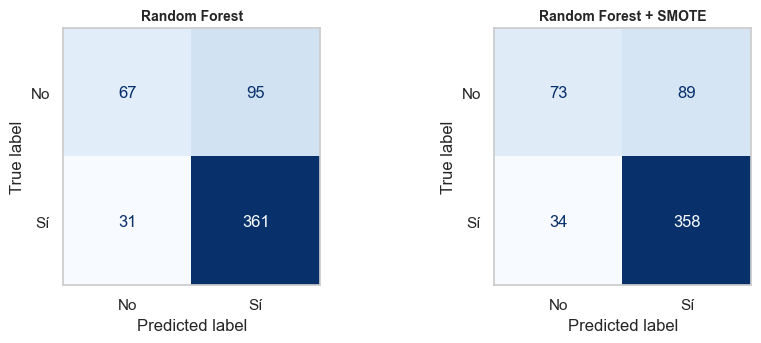

In [23]:
# Variante adicional sin datos sintéticos: Random Forest con pesos de clase (class_weight) y los hiperparámetros del modelo base
NOMBRE_CW = "Random Forest + class_weight"
mejores_base = {k: v for k, v in RES[(NOMBRE_RF, cupon)]["busqueda"].best_params_.items()}
pipe_cw = pipeline_rf().set_params(**mejores_base).set_params(clf__class_weight="balanced_subsample")
pipe_cw.fit(d["X_train"], d["y_train"])
pred_cw = pipe_cw.predict(d["X_test"])
m_cw = metricas_completas(d["y_test"], pred_cw)
RES[(NOMBRE_CW, cupon)] = dict(busqueda=None, pred=pred_cw, metricas=m_cw, modelo=pipe_cw)

filas = []
for nombre in [NOMBRE_RF, NOMBRE_SMOTE, NOMBRE_CW]:
    r = RES[(nombre, cupon)]
    filas.append({"Modelo": nombre, **r["metricas"]})
comp_smote = pd.DataFrame(filas).set_index("Modelo")[
    ["Precisión (No)", "Recall (No)", "F1 (No)", "Precisión (Sí)", "Recall (Sí)", "F1 (Sí)", "F1 macro", "Accuracy"]]
print("Resultados en el MISMO conjunto de test de Restaurante(<20) (n = %d; clase minoritaria 'No acepta' = %d)" %
      (len(d["y_test"]), (d["y_test"] == 0).sum()))
display(comp_smote.round(4).style.highlight_max(axis=0, color="#cde8cd"))

print("\nReporte de clasificación — sin balancear:")
print(classification_report(d["y_test"], RES[(NOMBRE_RF, cupon)]["pred"], target_names=["No acepta", "Sí acepta"], digits=3))
print("Reporte de clasificación — con SMOTE:")
print(classification_report(d["y_test"], RES[(NOMBRE_SMOTE, cupon)]["pred"], target_names=["No acepta", "Sí acepta"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, nombre in zip(axes, [NOMBRE_RF, NOMBRE_SMOTE]):
    ConfusionMatrixDisplay.from_predictions(d["y_test"], RES[(nombre, cupon)]["pred"], display_labels=["No", "Sí"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre, fontsize=10); ax.grid(False)
plt.tight_layout(); plt.show()

In [24]:
# ¿La diferencia es real o es ruido de una única partición? Se compara con validación cruzada repetida (5 × 3) sobre el train
multi = {"F1 (Sí)": "f1", "F1 macro": "f1_macro",
         "Recall (No)": make_scorer(recall_score, pos_label=0),
         "Precisión (No)": make_scorer(precision_score, pos_label=0, zero_division=0)}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

configs = {
    NOMBRE_RF:    RES[(NOMBRE_RF, cupon)]["busqueda"].best_estimator_,
    NOMBRE_SMOTE: RES[(NOMBRE_SMOTE, cupon)]["busqueda"].best_estimator_,
    NOMBRE_CW:    pipe_cw,
}
filas = []
for nombre, est in configs.items():
    cvr = cross_validate(clone(est), d["X_train"], d["y_train"], scoring=multi, cv=cv_rep, n_jobs=-1)
    fila = {"Modelo": nombre}
    for m in multi:
        v = cvr["test_" + m]; fila[m] = f"{v.mean():.3f} ± {v.std():.3f}"
    filas.append(fila)
print("Validación cruzada repetida (15 particiones) — media ± desviación")
display(pd.DataFrame(filas).set_index("Modelo"))

# Intervalo de confianza (bootstrap pareado sobre el test) de la diferencia SMOTE − sin balancear
y_t = d["y_test"].to_numpy()
p_base, p_smote = RES[(NOMBRE_RF, cupon)]["pred"], RES[(NOMBRE_SMOTE, cupon)]["pred"]
metricas_boot = {
    "Recall (No)": lambda y, p: recall_score(y, p, pos_label=0, zero_division=0),
    "Precisión (No)": lambda y, p: precision_score(y, p, pos_label=0, zero_division=0),
    "F1 (Sí)": lambda y, p: f1_score(y, p, pos_label=1, zero_division=0),
    "F1 macro": lambda y, p: f1_score(y, p, average="macro", zero_division=0),
}
rng = np.random.default_rng(SEED); n = len(y_t); B = 1000
idx = [rng.integers(0, n, n) for _ in range(B)]
filas = []
for nombre, f in metricas_boot.items():
    dif = np.array([f(y_t[i], p_smote[i]) - f(y_t[i], p_base[i]) for i in idx])
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas.append({"Métrica": nombre, "Diferencia (SMOTE − base)": f(y_t, p_smote) - f(y_t, p_base),
                  "IC 95 % inferior": lo, "IC 95 % superior": hi, "¿IC excluye 0?": not (lo <= 0 <= hi)})
print("\nBootstrap pareado (1000 remuestreos) sobre el conjunto de test")
display(pd.DataFrame(filas).set_index("Métrica").round(4))

Validación cruzada repetida (15 particiones) — media ± desviación


,F1 (Sí),F1 macro,Recall (No),Precisión (No)
Modelo,,,,
Random Forest,0.853 ± 0.010,0.695 ± 0.022,0.442 ± 0.037,0.684 ± 0.040
Random Forest + SMOTE,0.850 ± 0.007,0.697 ± 0.014,0.460 ± 0.027,0.665 ± 0.028
Random Forest + class_weight,0.851 ± 0.009,0.689 ± 0.019,0.430 ± 0.034,0.680 ± 0.036



Bootstrap pareado (1000 remuestreos) sobre el conjunto de test


,Diferencia (SMOTE − base),IC 95 % inferior,IC 95 % superior,¿IC excluye 0?
Métrica,,,,
Recall (No),0.0370,-0.0055,0.0784,False
Precisión (No),-0.0014,-0.0545,0.0484,False
F1 (Sí),0.0020,-0.0101,0.0133,False
F1 macro,0.0147,-0.0113,0.0407,False


### Análisis y recomendación — ¿conviene aplicar SMOTE?

**Resultados en test (n = 554; 162 casos de «No acepta»):**

| Modelo | Precisión (No) | **Recall (No)** | F1 (No) | F1 (Sí) | F1 macro |
|:--|:-:|:-:|:-:|:-:|:-:|
| Random Forest sin balancear | 0,684 | **0,414** | 0,515 | 0,851 | 0,683 |
| Random Forest + SMOTE | 0,663 | **0,414** | 0,510 | 0,847 | 0,678 |
| Random Forest + `class_weight` | 0,708 | 0,420 | 0,527 | 0,856 | 0,692 |

**Lectura.**
- SMOTE **no mejoró** el recall de la clase minoritaria en test (0,414 en ambos casos); la precisión de «No» bajó (0,684 → 0,663), y el F1 de «Sí» (0,851 → 0,847) y el F1 macro (0,683 → 0,678) disminuyeron ligeramente.
- Con validación cruzada repetida el recall de «No» sube un poco con SMOTE (0,442 → 0,460), pero a costa de precisión (0,684 → 0,665); el F1 macro es prácticamente igual (0,695 vs 0,697) y las desviaciones (≈ 0,03) son del mismo tamaño que las diferencias.
- El bootstrap pareado muestra que **los intervalos de confianza al 95 % de todas las diferencias incluyen el cero** (p. ej., recall de «No»: 0,000 [−0,035; +0,034]). No hay evidencia de que SMOTE cambie el desempeño.

**Recomendación: no aplicar SMOTE en este caso.** (1) No mejora de forma medible el recall de «No acepta» ni el F1 general; (2) añade complejidad y registros sintéticos poco realistas, porque se interpola sobre columnas One-Hot y ordinales y se generan valores fraccionarios que no corresponden a categorías reales; (3) el cuello de botella no es la *cantidad* de ejemplos de la clase minoritaria (810 registros) sino que los rechazos se parecen a las aceptaciones en las variables disponibles: la clase «No» está solapada con «Sí».

**Trade-off en el contexto del negocio.** Mejorar el recall de «No» significa identificar más conductores que rechazarían el cupón y no molestarlos, pero a costa de dejar de ofrecer cupones a quienes sí los aceptarían (menor precisión/recall de «Sí»). Si Ruta Alpes quiere reducir las notificaciones irrelevantes, es más efectivo **ajustar el umbral de decisión** o usar `class_weight` y calibrar la probabilidad con pruebas A/B, que generar datos sintéticos. El modelo sin balancear sigue siendo el seleccionado.

# 7. Tabla comparativa de modelos (test)

Las dos primeras tablas muestran el rendimiento en el conjunto de **test** (que no se usó en la búsqueda de hiperparámetros): la primera con las métricas solicitadas (precisión, recall y F1, clase positiva «Sí acepta») y la segunda con la clase «No acepta», el F1 macro, la exactitud, el F1 de validación cruzada y el F1 de entrenamiento (para diagnosticar sobreajuste). En Restaurante(<20) se incluye también la variante con SMOTE como referencia.

Después se hace una verificación de robustez: la validación cruzada **por perfil de conductor** (`GroupKFold`). El conjunto contiene varios escenarios por conductor; como no hay identificador, el perfil se aproxima con las variables demográficas y de hábitos, que son constantes entre escenarios de una misma persona.

TABLA COMPARATIVA — rendimiento sobre el conjunto de TEST (clase positiva = 'Sí acepta')



TABLA COMPLEMENTARIA — desempeño en la clase 'No acepta', métricas globales y diagnóstico de sobreajuste


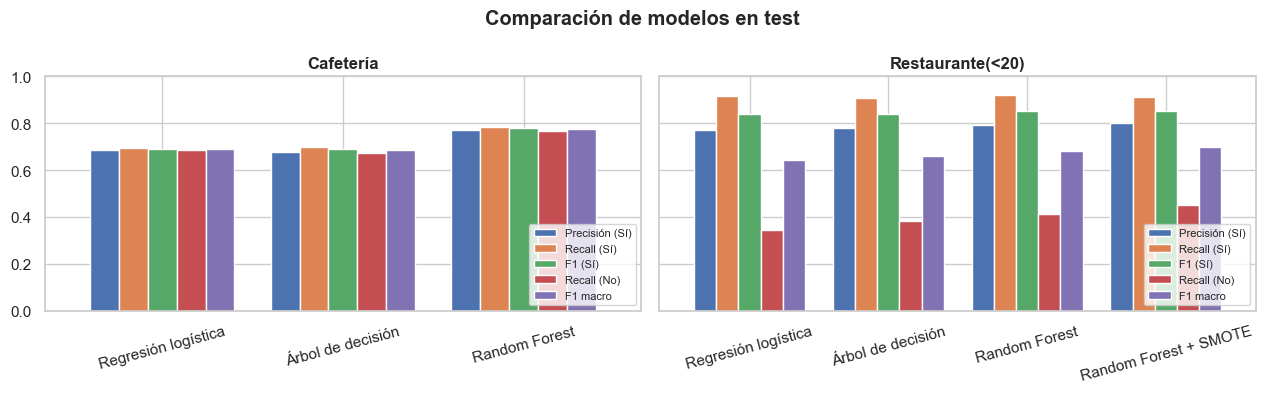

In [25]:
modelos_tabla = [NOMBRE_LR, NOMBRE_DT, NOMBRE_RF]
filas = []
for cupon in CUPONES:
    for nombre in modelos_tabla + ([NOMBRE_SMOTE] if cupon == "Restaurante(<20)" else []):
        filas.append({"Cupón": cupon, "Modelo": nombre, **RES[(nombre, cupon)]["metricas"]})
tabla = pd.DataFrame(filas)

print("TABLA COMPARATIVA — rendimiento sobre el conjunto de TEST (clase positiva = 'Sí acepta')")
tabla_principal = tabla[["Cupón", "Modelo", "Precisión (Sí)", "Recall (Sí)", "F1 (Sí)"]].rename(
    columns={"Precisión (Sí)": "Precisión", "Recall (Sí)": "Recall", "F1 (Sí)": "F1-score"})
display(tabla_principal.set_index(["Cupón", "Modelo"]).style.format("{:.4f}").highlight_max(axis=0, color="#cde8cd"))

print("\nTABLA COMPLEMENTARIA — desempeño en la clase 'No acepta', métricas globales y diagnóstico de sobreajuste")
display(tabla[["Cupón", "Modelo", "Precisión (No)", "Recall (No)", "F1 (No)", "F1 macro", "Accuracy", "F1 CV (train)", "F1 train"]]
        .set_index(["Cupón", "Modelo"]).style.format("{:.4f}").highlight_max(axis=0, color="#cde8cd"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, cupon in zip(axes, CUPONES):
    t = tabla[tabla["Cupón"] == cupon].set_index("Modelo")[["Precisión (Sí)", "Recall (Sí)", "F1 (Sí)", "Recall (No)", "F1 macro"]]
    t.plot.bar(ax=ax, rot=15, width=0.8)
    ax.set(title=cupon, ylim=(0, 1), xlabel=""); ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Comparación de modelos en test", fontweight="bold"); plt.tight_layout(); plt.show()

In [26]:
# --- ¿Cuánto del rendimiento se debe a conductores ya "vistos" en el entrenamiento? ---
# El conjunto contiene varios escenarios por conductor. Sin un identificador, se aproxima el "perfil de conductor"
# con la combinación de sus variables demográficas y de hábitos (constantes entre escenarios de la misma persona).
PERFIL_COLS = ["genero", "edad", "estado_civil", "tiene_hijos", "educacion", "ocupacion", "ingreso"] + \
              [c for c in COLUMNAS_MODELO if c.startswith("frecuencia_")]
def perfil_id(X):
    return pd.factorize(X[PERFIL_COLS].fillna("NA").astype(str).agg("|".join, axis=1))[0]

filas = []
for cupon in CUPONES:
    Xa, ya = DATOS[cupon]["X_all"], DATOS[cupon]["y_all"]
    g = perfil_id(Xa)
    print(f"{cupon}: {len(np.unique(g))} perfiles distintos para {len(Xa)} registros ({len(Xa)/len(np.unique(g)):.1f} escenarios por perfil)")
    for nombre in modelos_tabla:
        est = clone(RES[(nombre, cupon)]["busqueda"].best_estimator_)
        a = cross_validate(est, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=["f1", "f1_macro"], n_jobs=-1)
        b = cross_validate(est, Xa, ya, cv=GroupKFold(n_splits=5), groups=g, scoring=["f1", "f1_macro"], n_jobs=-1)
        filas.append({"Cupón": cupon, "Modelo": nombre,
                      "F1 (Sí) — CV aleatoria": a["test_f1"].mean(), "F1 (Sí) — CV por perfil": b["test_f1"].mean(),
                      "F1 macro — CV aleatoria": a["test_f1_macro"].mean(), "F1 macro — CV por perfil": b["test_f1_macro"].mean()})
grupo = pd.DataFrame(filas)
grupo["Caída F1 macro"] = grupo["F1 macro — CV aleatoria"] - grupo["F1 macro — CV por perfil"]
display(grupo.set_index(["Cupón", "Modelo"]).round(4))

# ¿Los conductores del archivo de prueba aparecen en los datos etiquetados?
perfiles_train = set(df[PERFIL_COLS].fillna("NA").astype(str).agg("|".join, axis=1))
perfiles_test = datos_prueba[PERFIL_COLS].fillna("NA").astype(str).agg("|".join, axis=1)
print(f"\nRegistros de Lab3_datos_Prueba cuyo perfil de conductor aparece en los datos etiquetados: {perfiles_test.isin(perfiles_train).mean():.0%}")

Cafetería: 565 perfiles distintos para 3979 registros (7.0 escenarios por perfil)
Restaurante(<20): 567 perfiles distintos para 2769 registros (4.9 escenarios por perfil)


F1 (Sí) — CV aleatoria  F1 (Sí) — CV por perfil  F1 macro — CV aleatoria  F1 macro — CV por perfil  Caída F1 macro
Cupón            Modelo                                                                                                                                 
Cafetería        Regresión logística                  0.6989                   0.6872                   0.7016                    0.6907          0.0109
                 Árbol de decisión                    0.7147                   0.7070                   0.6977                    0.6915          0.0062
                 Random Forest                        0.7709                   0.7011                   0.7690                    0.6946          0.0744
Restaurante(<20) Regresión logística                  0.8440                   0.8427                   0.6468                    0.6406          0.0062
                 Árbol de decisión                    0.8392                   0.8394                   0.6445                    0.6512         -0.0067
                 Random Forest                        0.8518                   0.8448                   0.6937                    0.6687          0.0251


Registros de Lab3_datos_Prueba cuyo perfil de conductor aparece en los datos etiquetados: 100%


### Selección del mejor modelo

| Cupón | Modelo | Precisión | Recall | F1 | Recall (No) | F1 macro |
|:--|:--|:-:|:-:|:-:|:-:|:-:|
| Cafetería | Regresión logística | 0,687 | 0,695 | 0,691 | 0,684 | 0,690 |
| Cafetería | Árbol de decisión | 0,679 | 0,698 | 0,688 | 0,672 | 0,685 |
| Cafetería | **Random Forest** | **0,770** | **0,786** | **0,778** | **0,767** | **0,776** |
| Restaurante(<20) | Regresión logística | 0,772 | 0,916 | 0,838 | 0,346 | 0,642 |
| Restaurante(<20) | Árbol de decisión | 0,781 | 0,908 | 0,840 | 0,383 | 0,658 |
| Restaurante(<20) | **Random Forest** | **0,792** | **0,921** | **0,851** | **0,414** | **0,683** |

**Random Forest es el mejor modelo en ambos cupones** en todas las métricas y también en F1 de validación cruzada (0,763 y 0,856), por lo que la elección no depende de una partición favorable.

- **Cafetería:** la diferencia es grande (+0,087 de F1 sobre la regresión logística) y simétrica entre clases.
- **Restaurante(<20):** la diferencia es pequeña (+0,011 a +0,013 de F1) y los tres modelos fallan en el mismo punto: detectan bien los «Sí» (recall ≈ 0,91-0,92) pero dejan pasar más de la mitad de los «No» (recall de «No» entre 0,35 y 0,41).

**Robustez (CV por perfil de conductor).** Cuando se evalúa con conductores que el modelo no vio en el entrenamiento, el F1 macro del Random Forest en Cafetería cae de 0,769 a 0,700 (−0,070), mientras que la regresión logística (0,702 → 0,690) y el árbol (0,698 → 0,691) casi no cambian; en Restaurante(<20) las caídas son pequeñas (RF: 0,694 → 0,673). Es decir, **parte de la ventaja del Random Forest en Cafetería proviene de reconocer perfiles ya vistos** (con hojas de una muestra puede "recordar" a un conductor). Esto no invalida la selección: el 100 % de los registros de `Lab3_datos_Prueba` corresponden a perfiles presentes en los datos etiquetados, que es justamente el escenario en el que el Random Forest rinde mejor. Pero para conductores nuevos (arranque en frío) el desempeño esperado es menor, y la ventaja del bosque sobre un modelo lineal se reduce a ≈ 0,01-0,02 de F1.

# 8. Variables más relevantes

Se usan tres técnicas complementarias, porque cada una responde algo distinto:
1. **Random Forest — importancia por permutación (sobre test, caída de AUC) e importancia por impureza (MDI)**, ambas agregadas por variable original (las columnas One-Hot se suman). La permutación mide cuánto empeora el modelo al romper la relación de una variable con la etiqueta; la MDI tiende a **inflar variables con muchas categorías** (como `ocupacion`) y a favorecer las correlacionadas, por eso no se usa sola.
2. **Regresión logística — signo y magnitud de los coeficientes** (variables estandarizadas): indican la **dirección** del efecto, algo que la importancia de un bosque no da.
3. **Árbol de decisión — reglas**: muestran cómo se combinan las variables.

Suma de MDI = 1.000
Suma de MDI = 1.000


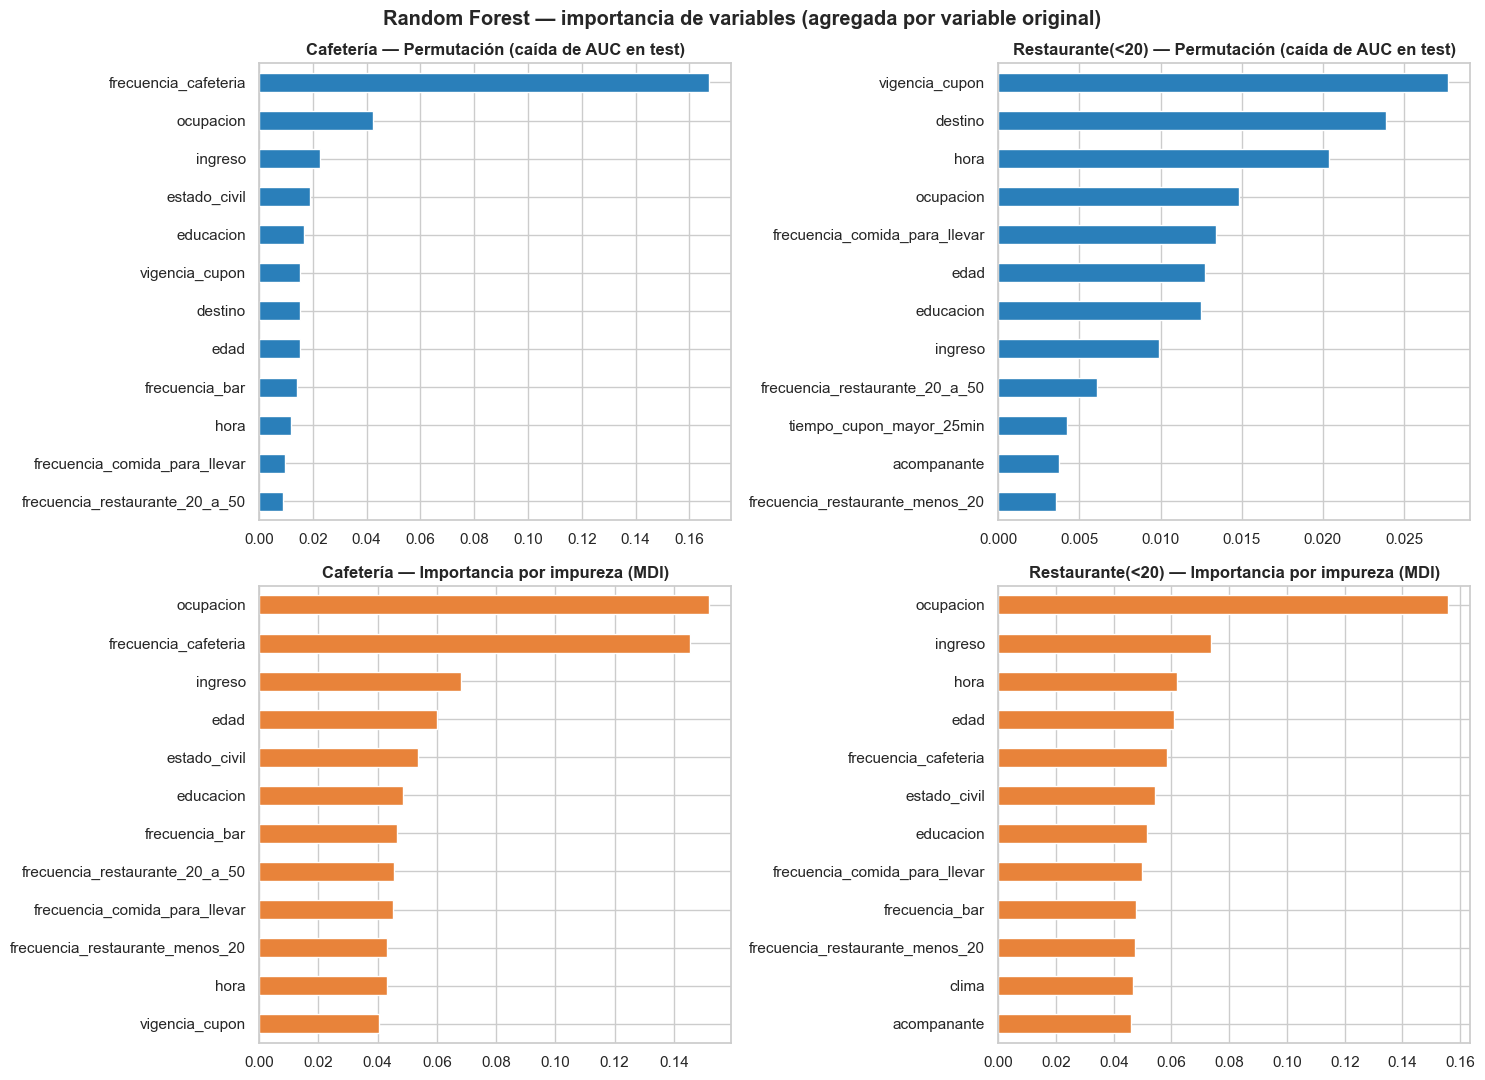

Comparación entre cupones (ordenada por la permutación en Cafetería):


Cafetería                            Restaurante(<20)                           
                                MDI (impureza) Permutación (ΔAUC) Ranking   MDI (impureza) Permutación (ΔAUC) Ranking
frecuencia_cafeteria                    0.1456             0.1672       1           0.0585             0.0008      18
ocupacion                               0.1517             0.0425       2           0.1556             0.0148       4
ingreso                                 0.0680             0.0228       3           0.0736             0.0099       8
estado_civil                            0.0535             0.0189       4           0.0542            -0.0033      21
educacion                               0.0484             0.0166       5           0.0516             0.0125       7
vigencia_cupon                          0.0403             0.0153       6           0.0410             0.0277       1
destino                                 0.0350             0.0152       7           0.0427             0.0239       2
edad                                    0.0602             0.0150       8           0.0608             0.0127       6
frecuencia_bar                          0.0466             0.0142       9           0.0476            -0.0004      19
hora                                    0.0432             0.0118      10           0.0618             0.0203       3
frecuencia_comida_para_llevar           0.0453             0.0097      11           0.0498             0.0134       5
frecuencia_restaurante_20_a_50          0.0454             0.0088      12           0.0444             0.0061       9
frecuencia_restaurante_menos_20         0.0433             0.0079      13           0.0473             0.0036      12
genero                                  0.0231             0.0079      14           0.0242             0.0029      13
acompanante                             0.0377             0.0065      15           0.0460             0.0037      11
temperatura                             0.0237             0.0047      16           0.0238             0.0027      15
misma_direccion                         0.0147             0.0037      17           0.0078             0.0026      16
tiene_hijos                             0.0181             0.0036      18           0.0167             0.0020      17
tiempo_cupon_mayor_25min                0.0126             0.0020      19           0.0271             0.0042      10
tiempo_cupon_mayor_15min                0.0275             0.0005      20           0.0187            -0.0014      20
clima                                   0.0160            -0.0004      21           0.0467             0.0028      14

In [27]:
def variable_original(nombre_col):
    n = re.sub(r"^(num|ord|nom)__", "", nombre_col)
    for c in sorted(COLUMNAS_MODELO, key=len, reverse=True):
        if n == c or n.startswith(c + "_"):
            return c
    return n

imp = {}
for cupon in CUPONES:
    d = DATOS[cupon]
    modelo = RES[(NOMBRE_RF, cupon)]["busqueda"].best_estimator_
    nombres = modelo.named_steps["prep"].get_feature_names_out()
    # (a) Importancia por impureza (MDI), sumada por variable original
    mdi = pd.Series(modelo.named_steps["clf"].feature_importances_, index=[variable_original(n) for n in nombres]).groupby(level=0).sum()
    # (b) Importancia por permutación sobre TEST (sobre las columnas originales; métrica AUC, independiente del umbral)
    perm = permutation_importance(modelo, d["X_test"], d["y_test"], scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
    perm = pd.Series(perm.importances_mean, index=d["X_test"].columns)
    imp[cupon] = pd.DataFrame({"MDI (impureza)": mdi, "Permutación (ΔAUC)": perm}).sort_values("Permutación (ΔAUC)", ascending=False)
    print(f"Suma de MDI = {mdi.sum():.3f}")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for j, cupon in enumerate(CUPONES):
    t = imp[cupon]
    t["Permutación (ΔAUC)"].sort_values().tail(12).plot.barh(ax=axes[0, j], color=COLOR_SI)
    axes[0, j].set(title=f"{cupon} — Permutación (caída de AUC en test)")
    t["MDI (impureza)"].sort_values().tail(12).plot.barh(ax=axes[1, j], color=COLOR_NO)
    axes[1, j].set(title=f"{cupon} — Importancia por impureza (MDI)")
plt.suptitle("Random Forest — importancia de variables (agregada por variable original)", fontweight="bold")
plt.tight_layout(); plt.show()

comp_imp = pd.concat({c: imp[c].assign(Ranking=lambda t: t["Permutación (ΔAUC)"].rank(ascending=False).astype(int)) for c in CUPONES}, axis=1)
comp_imp = comp_imp.sort_values((CUPONES[0], "Permutación (ΔAUC)"), ascending=False)
print("Comparación entre cupones (ordenada por la permutación en Cafetería):")
display(comp_imp.round(4))

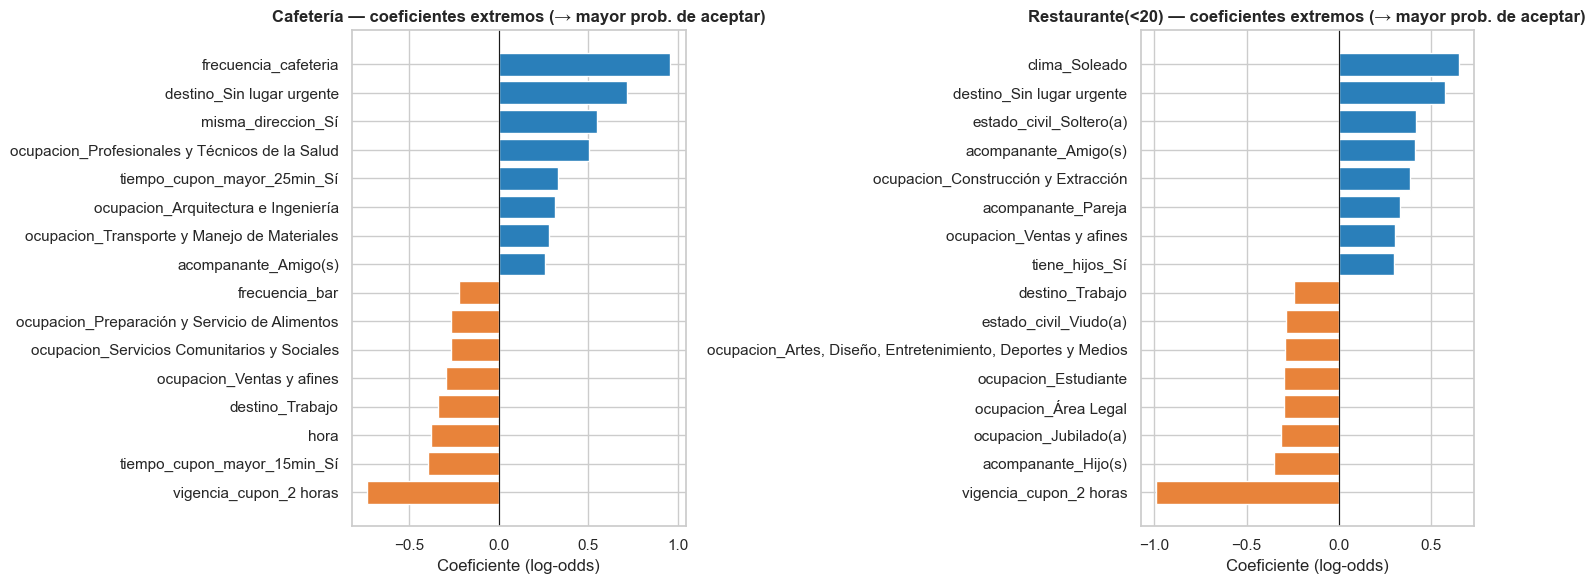


Cafetería: coeficientes que MÁS aumentan la probabilidad de aceptar


,coef
frecuencia_cafeteria,0.957
destino_Sin lugar urgente,0.715
misma_direccion_Sí,0.547
ocupacion_Profesionales y Técnicos de la Salud,0.505
tiempo_cupon_mayor_25min_Sí,0.329
ocupacion_Arquitectura e Ingeniería,0.316


Cafetería: coeficientes que MÁS la disminuyen


,coef
vigencia_cupon_2 horas,-0.733
tiempo_cupon_mayor_15min_Sí,-0.392
hora,-0.376
destino_Trabajo,-0.338
ocupacion_Ventas y afines,-0.293
ocupacion_Servicios Comunitarios y Sociales,-0.266



Restaurante(<20): coeficientes que MÁS aumentan la probabilidad de aceptar


,coef
clima_Soleado,0.650
destino_Sin lugar urgente,0.575
estado_civil_Soltero(a),0.419
acompanante_Amigo(s),0.414
ocupacion_Construcción y Extracción,0.386
acompanante_Pareja,0.334


Restaurante(<20): coeficientes que MÁS la disminuyen


,coef
vigencia_cupon_2 horas,-0.993
acompanante_Hijo(s),-0.350
ocupacion_Jubilado(a),-0.316
ocupacion_Área Legal,-0.299
ocupacion_Estudiante,-0.296
"ocupacion_Artes, Diseño, Entretenimiento, Deportes y Medios",-0.291


In [28]:
# Regresión logística: signo y magnitud de los coeficientes (variables estandarizadas → comparables entre sí)
coefs = {}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cupon in zip(axes, CUPONES):
    modelo = RES[(NOMBRE_LR, cupon)]["busqueda"].best_estimator_
    nombres = [re.sub(r"^(num|ord|nom)__", "", n) for n in modelo.named_steps["prep"].get_feature_names_out()]
    coef = pd.Series(modelo.named_steps["clf"].coef_[0], index=nombres).sort_values()
    coefs[cupon] = coef
    extremos = pd.concat([coef.head(8), coef.tail(8)])
    ax.barh(extremos.index, extremos.values, color=[COLOR_NO if v < 0 else COLOR_SI for v in extremos.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"{cupon} — coeficientes extremos (→ mayor prob. de aceptar)", xlabel="Coeficiente (log-odds)")
plt.tight_layout(); plt.show()

for cupon in CUPONES:
    c = coefs[cupon]
    print(f"\n{cupon}: coeficientes que MÁS aumentan la probabilidad de aceptar")
    display(c.tail(6)[::-1].round(3).to_frame("coef"))
    print(f"{cupon}: coeficientes que MÁS la disminuyen")
    display(c.head(6).round(3).to_frame("coef"))

REGLAS DEL ÁRBOL — Cafetería  (profundidad 5, 29 hojas; se muestran 3 niveles)
|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- ocupacion_Computación y Matemáticas <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- ocupacion_Computación y Matemáticas >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- destino_Casa <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- destino_Casa >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |--- ingreso >  5.50
|   |   |--- ocupacion_Arquitectura e Ingeniería <= 0.50
|   |   |   |--- frecuencia_comida_para_llevar <= 1.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- frecuencia_comida_para_llevar >  1.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- ocupacion_Arquitectura e Ingeniería >  0.50
|   |   |   |--- 

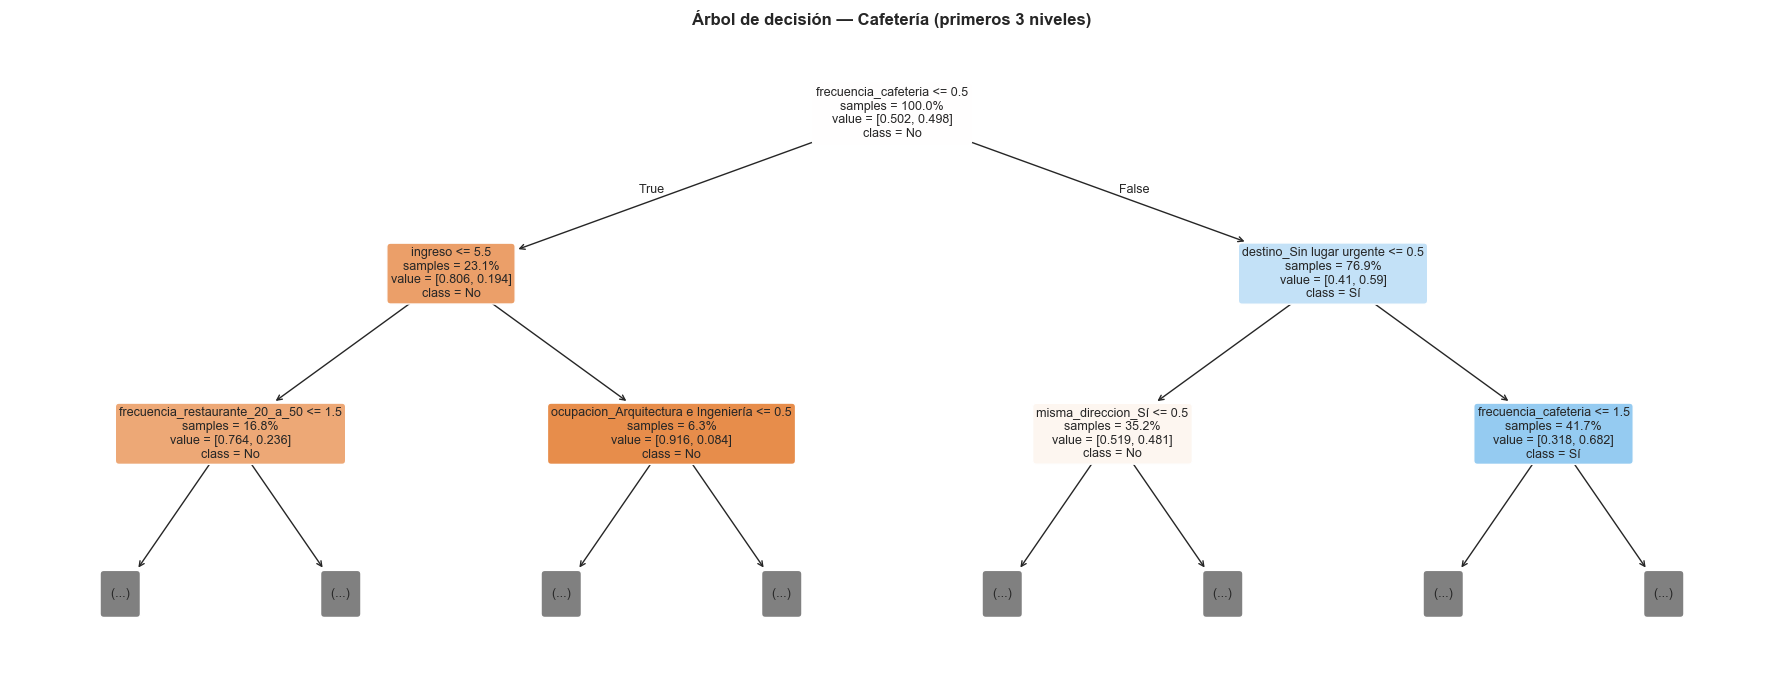

REGLAS DEL ÁRBOL — Restaurante(<20)  (profundidad 3, 8 hojas; se muestran 3 niveles)
|--- tiempo_cupon_mayor_25min_Sí <= 0.50
|   |--- vigencia_cupon_2 horas <= 0.50
|   |   |--- temperatura <= 42.50
|   |   |   |--- class: Sí
|   |   |--- temperatura >  42.50
|   |   |   |--- class: Sí
|   |--- vigencia_cupon_2 horas >  0.50
|   |   |--- hora <= 3.50
|   |   |   |--- class: Sí
|   |   |--- hora >  3.50
|   |   |   |--- class: No
|--- tiempo_cupon_mayor_25min_Sí >  0.50
|   |--- acompanante_Pareja <= 0.50
|   |   |--- frecuencia_cafeteria <= 3.50
|   |   |   |--- class: No
|   |   |--- frecuencia_cafeteria >  3.50
|   |   |   |--- class: No
|   |--- acompanante_Pareja >  0.50
|   |   |--- estado_civil_Casado(a) <= 0.50
|   |   |   |--- class: Sí
|   |   |--- estado_civil_Casado(a) >  0.50
|   |   |   |--- class: Sí



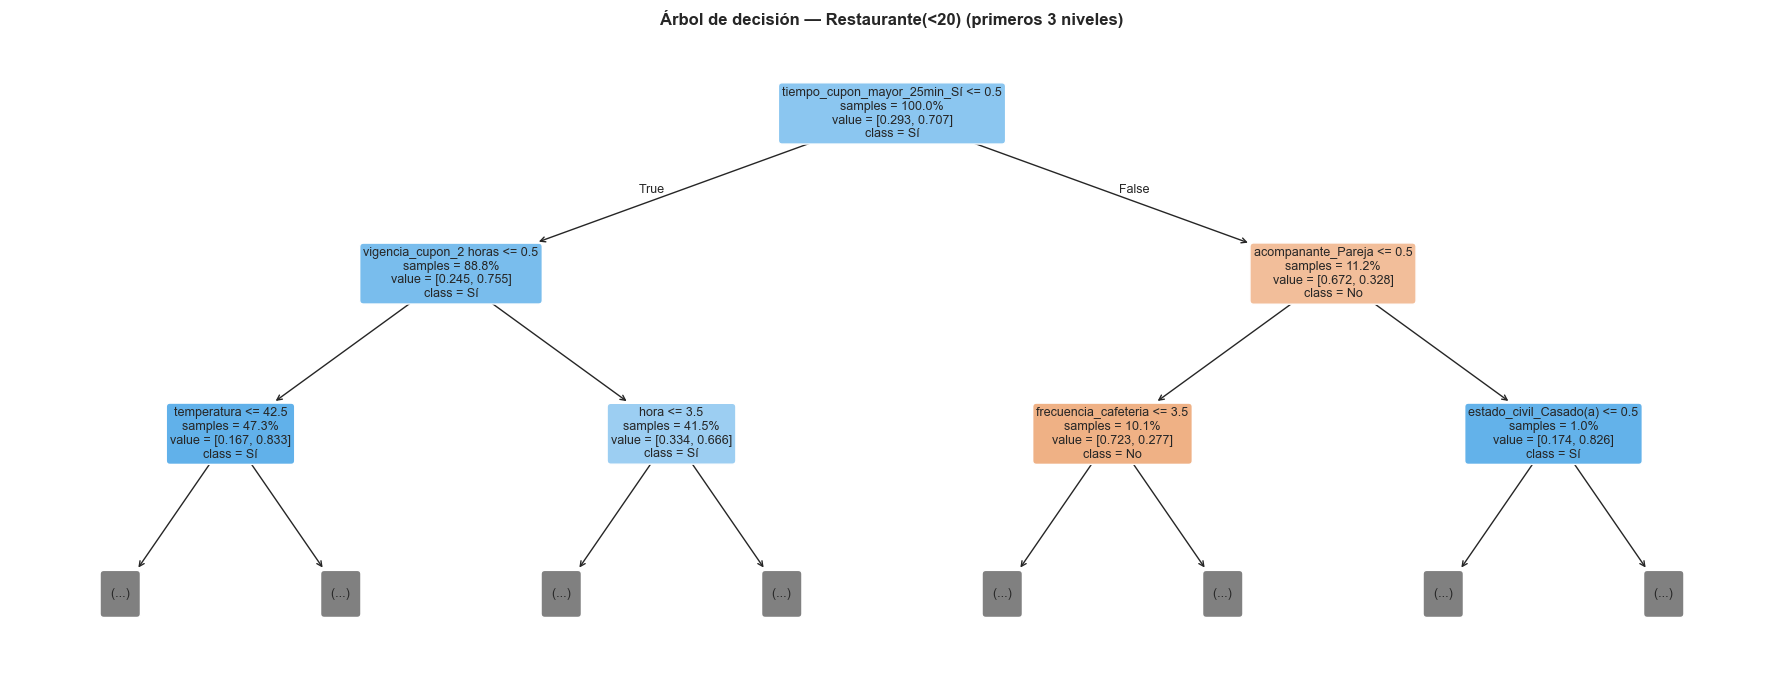

In [29]:
# Reglas de decisión del árbol (mejor árbol por cupón). Los umbrales están en el código ordinal de cada variable:
# frecuencias: 0=nunca, 1=menos de 1, 2=1 a 3, 3=4 a 8, 4=más de 8 | hora: 0=7am, 1=10am, 2=2pm, 3=6pm, 4=10pm
for cupon in CUPONES:
    modelo = RES[(NOMBRE_DT, cupon)]["busqueda"].best_estimator_
    nombres = [re.sub(r"^(num|ord|nom)__", "", n) for n in modelo.named_steps["prep"].get_feature_names_out()]
    arbol = modelo.named_steps["clf"]
    print("=" * 78); print(f"REGLAS DEL ÁRBOL — {cupon}  (profundidad {arbol.get_depth()}, {arbol.get_n_leaves()} hojas; se muestran 3 niveles)"); print("=" * 78)
    print(export_text(arbol, feature_names=nombres, max_depth=3, class_names=["No", "Sí"]))

    fig, ax = plt.subplots(figsize=(18, 7))
    plot_tree(arbol, feature_names=nombres, class_names=["No", "Sí"], max_depth=2, filled=True, rounded=True, fontsize=9, ax=ax, impurity=False, proportion=True)
    ax.set_title(f"Árbol de decisión — {cupon} (primeros 3 niveles)")
    plt.tight_layout(); plt.show()

### Interpretación

**Cafetería.** La variable dominante es **`frecuencia_cafeteria`**: su permutación reduce el AUC en 0,167, casi cuatro veces más que la segunda (`ocupacion`, 0,043); le siguen `ingreso` (0,023), `estado_civil` (0,019), `educacion` (0,017) y `vigencia_cupon` (0,015). Su coeficiente en la regresión logística es el mayor (+0,96): entre quienes visitan cafeterías con frecuencia aceptan 65-69 %, entre quienes nunca van solo 19 %. También aumentan la aceptación `destino = Sin lugar urgente` (+0,72) y `misma_direccion = Sí` (+0,55); la disminuyen la vigencia de 2 horas (−0,73), un local a más de 15 min (−0,39), `destino = Trabajo` (−0,34) y horas tardías (`hora`, −0,38).

**Restaurante(<20).** Aquí dominan las variables de **contexto**: `vigencia_cupon` (0,028), `destino` (0,024), `hora` (0,020), `ocupacion` (0,015), `frecuencia_comida_para_llevar` (0,013), `edad` (0,013) y `educacion` (0,013); los hábitos de cafeterías, bares o restaurantes caros casi no aportan (`frecuencia_cafeteria` ≈ 0,001, posición 18). En la regresión logística el cupón de 2 horas reduce fuertemente la aceptación (−0,99), y la favorecen el clima soleado (+0,65), el destino «sin lugar urgente» (+0,58), ir con amigos (+0,41) o pareja (+0,33) y ser soltero(a) (+0,42); ir con hijos (−0,35) la reduce. El árbol añade que un local a más de 25 minutos aleja la aceptación (33 % frente a 75 %).

**Comparación.** En Cafetería la aceptación se explica sobre todo por el **hábito del conductor** (si ya es consumidor de café); en Restaurante(<20) por el **momento y las circunstancias del viaje** (cuánto tiempo hay, cuánto dura el cupón, con quién va, clima). Esto tiene sentido: el café es un consumo de preferencia personal, mientras que una comida requiere disponibilidad de tiempo y compañía. Comparten `vigencia_cupon`, `destino`, `ocupacion`, `educacion` y `edad`.

**Precaución.** La importancia (permutación o MDI) indica cuánto usa el modelo una variable, **no la dirección ni la causalidad**; los coeficientes dan dirección pero dependen de la codificación y de las correlaciones entre variables (p. ej., `destino`–`hora`, V = 0,83). Además, la MDI de `ocupacion` (0,15 en ambos cupones) es mucho mayor que su importancia por permutación (0,043 y 0,015): es un artefacto de sus 25 categorías.

#### Reglas del árbol de decisión
- **Restaurante(<20)** (árbol de profundidad 3, 8 hojas): si el local está a **más de 25 min**, se predice «No», **salvo** que el conductor viaje con su pareja (entonces «Sí»). Si está a menos de 25 min y el cupón dura **1 día**, se predice «Sí»; si dura **2 horas**, «Sí» hasta las 6 p.m. y «No» a las 10 p.m.
- **Cafetería** (profundidad 5, 29 hojas): la primera división es `frecuencia_cafeteria ≤ 0,5` (quien "nunca" va a cafeterías); en esa rama la decisión depende del ingreso y de la ocupación. En la rama de quienes sí van, se separa por `destino = Sin lugar urgente` y por `vigencia_cupon`/`hora`, con aceptación más probable cuando no hay un destino urgente.

# 9. Predicciones sobre `Lab3_datos_Prueba`

Se selecciona el mejor modelo por cupón (mayor F1 en test), se **reajusta con todos los datos etiquetados de ese cupón** usando los hiperparámetros ya validados, y cada registro del archivo de prueba se predice **con el modelo de su propio tipo de cupón**. El resultado se guarda en `Lab3_datos_Prueba.csv`: el archivo original más la columna `acepta_cupon` (`Sí` / `No`).

In [30]:
# 1. Selección del mejor modelo por cupón: mayor F1 (Sí) en test entre los tres algoritmos requeridos
candidatos = tabla[tabla["Modelo"].isin(modelos_tabla)]
MEJOR = candidatos.loc[candidatos.groupby("Cupón")["F1 (Sí)"].idxmax()].set_index("Cupón")["Modelo"].to_dict()
print("Mejor modelo por cupón:", MEJOR)

# 2. Se reajusta cada mejor pipeline (con sus hiperparámetros ya validados) con TODOS los datos etiquetados del cupón
modelos_finales = {c: clone(RES[(MEJOR[c], c)]["busqueda"].best_estimator_).fit(DATOS[c]["X_all"], DATOS[c]["y_all"]) for c in CUPONES}

# 3. Control de calidad del archivo de prueba y predicción: cada registro se predice con el modelo de SU tipo de cupón
for col, orden in ORD.items():
    assert set(datos_prueba[col].dropna()) <= set(orden), f"categorías no reconocidas en {col}"
assert set(datos_prueba["cupon"]) <= set(CUPONES), "hay cupones distintos a Cafetería / Restaurante(<20)"
print("Registros de prueba por cupón:", datos_prueba["cupon"].value_counts().to_dict())

salida = datos_prueba.copy()
salida["acepta_cupon"] = pd.Series(index=salida.index, dtype=object)
salida["prob_acepta"] = np.nan
for cupon in CUPONES:
    mask = salida["cupon"] == cupon
    Xp = salida.loc[mask, COLUMNAS_MODELO]
    salida.loc[mask, "prob_acepta"] = modelos_finales[cupon].predict_proba(Xp)[:, 1]
    salida.loc[mask, "acepta_cupon"] = np.where(modelos_finales[cupon].predict(Xp) == 1, "Sí", "No")

assert salida["acepta_cupon"].notna().all() and len(salida) == len(datos_prueba)
salida_csv = salida.drop(columns="prob_acepta")           # el archivo entregable = archivo original + columna acepta_cupon
salida_csv.to_csv("Lab3_datos_Prueba.csv", index=False, encoding="utf-8")
print("\n Archivo generado: Lab3_datos_Prueba.csv  |", salida_csv.shape[0], "filas ×", salida_csv.shape[1], "columnas")

display(salida[["cupon", "destino", "acompanante", "hora", "prob_acepta", "acepta_cupon"]].round(3))
display(pd.crosstab(salida["cupon"], salida["acepta_cupon"]))

# Verificación: se relee el CSV y se comprueba que conserva columnas originales + la nueva
chequeo = pd.read_csv("Lab3_datos_Prueba.csv")
assert list(chequeo.columns) == list(datos_prueba.columns) + ["acepta_cupon"]
print("Columnas del CSV:", list(chequeo.columns)[-3:], "... (+ las originales)")

Mejor modelo por cupón: {'Cafetería': 'Random Forest', 'Restaurante(<20)': 'Random Forest'}
Registros de prueba por cupón: {'Cafetería': 10, 'Restaurante(<20)': 10}

 Archivo generado: Lab3_datos_Prueba.csv  | 20 filas × 26 columnas


,cupon,destino,acompanante,hora,prob_acepta,acepta_cupon
0,Cafetería,Trabajo,Solo,7:00 a.m.,0.493,No
1,Cafetería,Sin lugar urgente,Amigo(s),10:00 a.m.,0.727,Sí
2,Cafetería,Sin lugar urgente,Amigo(s),2:00 p.m.,0.872,Sí
3,Cafetería,Sin lugar urgente,Pareja,10:00 a.m.,0.875,Sí
4,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,0.940,Sí
5,Restaurante(<20),Sin lugar urgente,Hijo(s),2:00 p.m.,0.910,Sí
6,Restaurante(<20),Sin lugar urgente,Solo,2:00 p.m.,0.200,No
7,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,0.830,Sí
8,Restaurante(<20),Sin lugar urgente,Amigo(s),2:00 p.m.,0.940,Sí
9,Cafetería,Casa,Solo,6:00 p.m.,0.204,No


acepta_cupon,No,Sí
cupon,,
Cafetería,4,6
Restaurante(<20),1,9


Columnas del CSV: ['misma_direccion', 'direccion_opuesta', 'acepta_cupon'] ... (+ las originales)


**Resultado.** El archivo de prueba tiene 20 registros (10 de Cafetería y 10 de Restaurante(<20)). Se predijo aceptación en 6 de 10 cupones de Cafetería y en 9 de 10 de Restaurante(<20), proporciones coherentes con las tasas históricas (≈ 50 % y ≈ 71 %). Las predicciones son salidas del modelo, no tasas reales de aceptación, y con solo 20 registros cualquier métrica sobre ellas tendrá mucha varianza. Todos los perfiles de conductor del archivo existen en los datos de entrenamiento, que es la condición en la que Random Forest ofrece su mejor desempeño.

# Análisis de resultados

### 1. ¿Qué características del contexto de conducción o del perfil del conductor se relacionan más con la aceptación?

**Cafetería:** sobre todo un rasgo del **perfil/hábito**: `frecuencia_cafeteria`. Su importancia por permutación (ΔAUC 0,167) es casi cuatro veces la de la siguiente (`ocupacion`, 0,043), y la asociación univariada es la más alta (V = 0,38): acepta 19 % de quienes nunca van a cafeterías frente a 65-69 % de quienes van con frecuencia. En el **contexto**, favorecen la aceptación viajar sin un destino urgente (58 % vs 36 % si va a casa), con amigos (60 % vs 44 % solo) y un cupón de 1 día (58 % vs 43 % de 2 horas). Después aparecen perfil (`ocupacion`, `ingreso`, `estado_civil`, `educacion`).

**Restaurante(<20):** pesan más las variables de **contexto**: vigencia del cupón (83 % de aceptación con 1 día vs 59 % con 2 horas), destino (79 % «sin lugar urgente»), hora (83 % a las 6 p.m. vs 51 % a las 10 p.m.), clima (77 % soleado vs 40 % lluvioso) y distancia (33 % si el local está a más de 25 min vs 75 %). Los hábitos de consumo de cafeterías o bares casi no importan.

La importancia no implica causalidad ni dirección; la dirección proviene de los coeficientes y de las tasas por categoría.

### 2. ¿Existen variables redundantes o poco informativas?

Sí, con evidencia:
- **Redundancia exacta:** `misma_direccion` y `direccion_opuesta` (V = 1,00; se descartó una). `tiempo_cupon_mayor_5min` es constante (varianza cero; se descartó) y `tiempo_cupon_mayor_25min` implica `tiempo_cupon_mayor_15min`.
- **Redundancia fuerte:** `destino`–`hora` (V = 0,83), `clima`–`temperatura` (0,67), `estado_civil`–`tiene_hijos` (0,57) y `destino`–`acompanante` (0,52). Las frecuencias de consumo se correlacionan de forma débil a moderada (p. ej., ρ de Spearman = 0,37 entre restaurantes <20 y de 20-50; mapa de 1.9).
- **Poco informativas:** `tiene_hijos` y `genero` (V ≈ 0,00-0,01 con la aceptación y permutación ≈ 0,003); `clima` y `tiempo_cupon_mayor_15min` en Cafetería (permutación ≈ 0); `frecuencia_cafeteria`, `frecuencia_bar` y `estado_civil` en Restaurante(<20) (permutación ≈ 0 o negativa: barajar la variable no empeora el modelo). `vehiculo` se descartó por tener 99 % de faltantes.
- **Cautela:** una variable poco informativa en un cupón puede serlo en otro (`frecuencia_cafeteria` es la principal en Cafetería y casi nula en Restaurante). Una estimación definitiva requeriría reentrenar sin ellas y comparar con validación cruzada. Eliminarlas simplificaría el modelo y, además, reduciría la dependencia de variables sensibles como `genero`.

### 3. ¿El desempeño y el comportamiento difieren entre Cafetería y Restaurante(<20)? ¿Por qué?

Sí. Con Random Forest el F1 de la clase «Sí» es 0,778 en Cafetería y 0,851 en Restaurante(<20); pero **este segundo número no significa que el modelo sea mejor**: el F1 macro es 0,776 en Cafetería y 0,683 en Restaurante(<20), y el recall de «No» es 0,767 frente a 0,414. Las razones:
1. **Distribución de clases.** Cafetería está balanceada (50/50), así que predecir «Sí» no es "gratis". En Restaurante(<20) el 70,7 % son «Sí»: un modelo que casi siempre diga «Sí» ya obtiene un F1 alto en esa clase (0,83-0,85), aunque deje pasar los rechazos (recall de «No» entre 0,35 y 0,41 en los tres algoritmos).
2. **Naturaleza de la señal.** En Cafetería hay una variable de hábito muy informativa (`frecuencia_cafeteria`) que separa las clases y permite que el bosque mejore +0,09 de F1 frente a los modelos simples. En Restaurante(<20) la señal está en el contexto del viaje, que se comparte entre conductores y se solapa entre clases, así que los tres algoritmos rinden parecido (diferencias ≤ 0,013).
3. **Memorización de perfiles.** La ventaja del bosque en Cafetería depende en parte de repetidos conductores (F1 macro de 0,769 a 0,700 al validar por perfil); en Restaurante(<20) apenas cambia (0,694 → 0,673).

### 4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo?

**No.** En test, SMOTE dejó el recall de la clase minoritaria «No acepta» igual (0,414 → 0,414), bajó la precisión de «No» (0,684 → 0,663), y redujo ligeramente el F1 de «Sí» (0,851 → 0,847) y el F1 macro (0,683 → 0,678). En validación cruzada repetida el recall de «No» pasa de 0,442 a 0,460 pero con menor precisión, y el bootstrap pareado muestra que ningún cambio es distinguible de cero (intervalos de confianza al 95 % que incluyen el 0). Por tanto, **no se recomienda aplicar SMOTE**. El techo del modelo se debe al solapamiento entre clases, no a la escasez de ejemplos; las alternativas razonables son ajustar el umbral de decisión según el costo de molestar con un cupón no deseado o incorporar variables más informativas.

### 5. Reglas o importancia de variables desde un árbol / Random Forest, con su utilidad y limitaciones

**Reglas del árbol (Restaurante(<20), 8 hojas):** (i) si el local está a más de 25 min → rechazo, salvo si viaja con su pareja; (ii) si está a menos de 25 min con cupón de 1 día → aceptación; (iii) con cupón de 2 horas → aceptación hasta las 6 p.m. y rechazo a las 10 p.m. **Árbol de Cafetería:** primero separa a quienes nunca visitan cafeterías (rama con aceptación baja que solo se revierte con ingreso alto o ciertas ocupaciones) y, entre quienes sí lo hacen, separa por destino sin urgencia y por vigencia del cupón. **Random Forest:** `frecuencia_cafeteria` domina Cafetería; `vigencia_cupon`, `destino` y `hora` dominan Restaurante(<20).

**Utilidad:** las reglas son comprensibles para el negocio (p. ej. «no ofrecer restaurantes a más de 25 min si va solo»); la importancia indica qué datos capturar y cuáles se pueden dejar de recolectar.
**Limitaciones:** la importancia no da dirección ni causalidad; las MDI se sesgan hacia variables con muchas categorías (`ocupacion`) y correlacionadas (`destino`–`hora`); un árbol es inestable y mostrar solo 3 niveles omite combinaciones; los árboles de poco nivel no alcanzan el desempeño del bosque (que no es interpretable regla a regla), y los patrones describen asociación en una encuesta, no causalidad.

### 6. ¿Cómo integrar el modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

1. **Entradas disponibles en el momento:** hora, destino (de la ruta), acompañante, clima, distancia/tiempo al local y dirección respecto a la ruta (datos que la app ya conoce) más el perfil/hábitos guardados del conductor.
2. **Servicio de scoring:** el pipeline completo (preprocesamiento + modelo) se guarda con `joblib` y se expone como un microservicio; un bosque de 100-300 árboles predice en milisegundos. Cada tipo de cupón tiene su modelo; la app calcula la probabilidad de aceptación de cada uno y muestra el de mayor probabilidad (idealmente ponderada por el margen de negocio), solo si supera un **umbral** calibrado.
3. **Seguridad y experiencia:** mostrar ofertas solo en momentos seguros (antes de arrancar o con el vehículo detenido), limitar la frecuencia y permitir silenciar la personalización.
4. **Operación:** registrar si el conductor aceptó para **reentrenar periódicamente**, monitorear la deriva (cambios en la distribución de entradas o de la tasa de aceptación), hacer pruebas A/B contra una estrategia base y definir una oferta por defecto para conductores nuevos (arranque en frío), para los cuales los resultados por perfil sugieren un rendimiento menor.

### 7. Limitaciones de un sistema automático que decide ofertas según el perfil demográfico

- **Validez de los datos:** provienen de una encuesta con escenarios hipotéticos: miden intención declarada, no conducta real; las respuestas de un mismo conductor se repiten (~5-7 escenarios por perfil por cupón), y existe ruido irreducible (23 grupos de predictores idénticos con etiquetas contradictorias).
- **Generalización:** los modelos rinden mejor con conductores ya vistos; con conductores nuevos el desempeño baja (hasta −0,07 de F1 macro en Cafetería). Las preferencias cambian con el tiempo (deriva).
- **Calidad predictiva moderada:** en Restaurante(<20) el modelo detecta menos de la mitad de los rechazos, así que seguiría mostrando cupones no deseados a muchos usuarios.
- **Retroalimentación:** si solo se muestran las ofertas que el modelo cree aceptables, los datos futuros quedan sesgados por las decisiones del propio modelo y se pierde la exploración.
- **Privacidad y transparencia:** usar edad, estado civil, ingresos u ocupación exige consentimiento, minimización de datos y la posibilidad de desactivar la personalización; además, un bosque es difícil de explicar a cada usuario.

### 8. Fuentes de sesgo y personalización con fines distintos

**Fuentes de sesgo en datos y modelado:**
1. **Muestreo y representación:** la encuesta no es una muestra aleatoria de conductores; algunas categorías tienen muy pocos casos (`Bachillerato incompleto`: 88; `Viudo(a)`: 130; ocupaciones con <1 %), de modo que las predicciones para esos grupos son poco fiables.
2. **Sesgo de medición:** las respuestas son hipotéticas y autorreportadas.
3. **Variables proxy:** `ocupacion`, `ingreso`, `educacion` y `edad` están entre las más importantes para el modelo (p. ej. `ocupacion` y `edad` en ambos cupones); aunque no se use explícitamente el género, ocupación, estado civil o ingreso pueden actuar como proxy de nivel socioeconómico, género u origen.
4. **Sesgo histórico y de agregación:** el modelo aprende que ciertos grupos aceptan menos y puede perpetuarlo (menos ofertas para ellos), y un único modelo global puede funcionar mejor para unos grupos que para otros. Este trabajo **no** midió el desempeño por grupo; para ello habría que calcular recall, precisión y tasa de ofertas por género, edad e ingreso.
5. **Repetición de conductores:** como los mismos conductores aparecen en entrenamiento y prueba, las métricas pueden sobrestimar el desempeño real (sesgo de evaluación).

**Implicaciones si se usara para precios dinámicos, créditos u otros fines:** una oferta irrelevante cuesta poco, pero un precio, una tasa o un acceso a servicio basado en un perfil demográfico puede **discriminar** (cobrar más a quien se estima menos sensible al precio o con menos alternativas), vulnerar normas de protección al consumidor y de datos personales, y generar efectos de círculo vicioso. En esos casos habría que excluir variables sensibles y sus proxies, auditar equidad por grupo, exigir explicabilidad y supervisión humana, y evaluar el impacto antes de desplegar.

# Uso de herramientas de IA generativa


## A. ChatGPT (OpenAI) — desarrollo inicial del laboratorio

**1. Declaración del uso.** ChatGPT se empleó como apoyo para generar una estructura inicial de código en Python, explicar métricas y técnicas de clasificación, depurar errores, interpretar resultados y ayudar a redactar conclusiones. Usos principales: ayuda conceptual sobre evaluación de modelos de clasificación; generación inicial de código de regresión logística, árboles y Random Forest; apoyo en la búsqueda de hiperparámetros con validación cruzada; depuración del cálculo de importancias y de las predicciones.

**2. Prompts principales.**
- «Para el modelo de Restaurante(<20), evaluar si aplicar una técnica de balanceo de clases, por ejemplo SMOTE, mejora el desempeño frente al modelo sin balancear. Comparar el F1-score y el recall de la clase minoritaria y concluir si conviene aplicar la técnica.»
- «Elaborar una tabla comparativa del rendimiento en test de regresión logística, árbol de decisión y Random Forest para cada tipo de cupón, usando recall, precisión y F1-score.»
- «Ayudar a interpretar los resultados obtenidos.»
- «Corregir el código cuando aparezcan errores y utilizar las variables y estructuras que ya existen en el entorno de trabajo.»

**3. Análisis crítico.** El primer código de importancia de variables interpretó mal las tuplas del preprocesador (un `TypeError` al aplicar `len()` a un `SimpleImputer`) y una primera tabla comparativa usaba nombres de variables inexistentes; se corrigieron al revisar los objetos reales. El código generado no debe ejecutarse sin revisión.

**4. Aportes propios del estudiante.** 
- Definición del protocolo experimental, incluyendo partición de datos, preprocesamiento y métricas de evaluación.
- Construcción y validación de los modelos de regresión logística y árboles de decisión para ambos objetivos.
- Ejecución de la búsqueda de hiperparámetros con validación cruzada y comparación de resultados sobre test.
- Identificación e interpretación de las variables más relevantes según cada modelo.
- Redacción del análisis final con base en los resultados obtenidos y en las preguntas planteadas en el enunciado.